# TritFlow: balanced-ternary HDL to GDS on OpenSUSI TR-1um

TritFlow turns balanced-ternary HDL into checked GDS and extracted SPICE
waveforms on Japan's [OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um).
Its library adapts the [author's taped-out ternary cells](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic).
**Choose Runtime → Run all** to follow an adder from its middle-voltage
divider to layout, then edit your own circuit.

The reference cells were taped out in 2026; silicon is
expected in January 2027 and has not yet been measured.



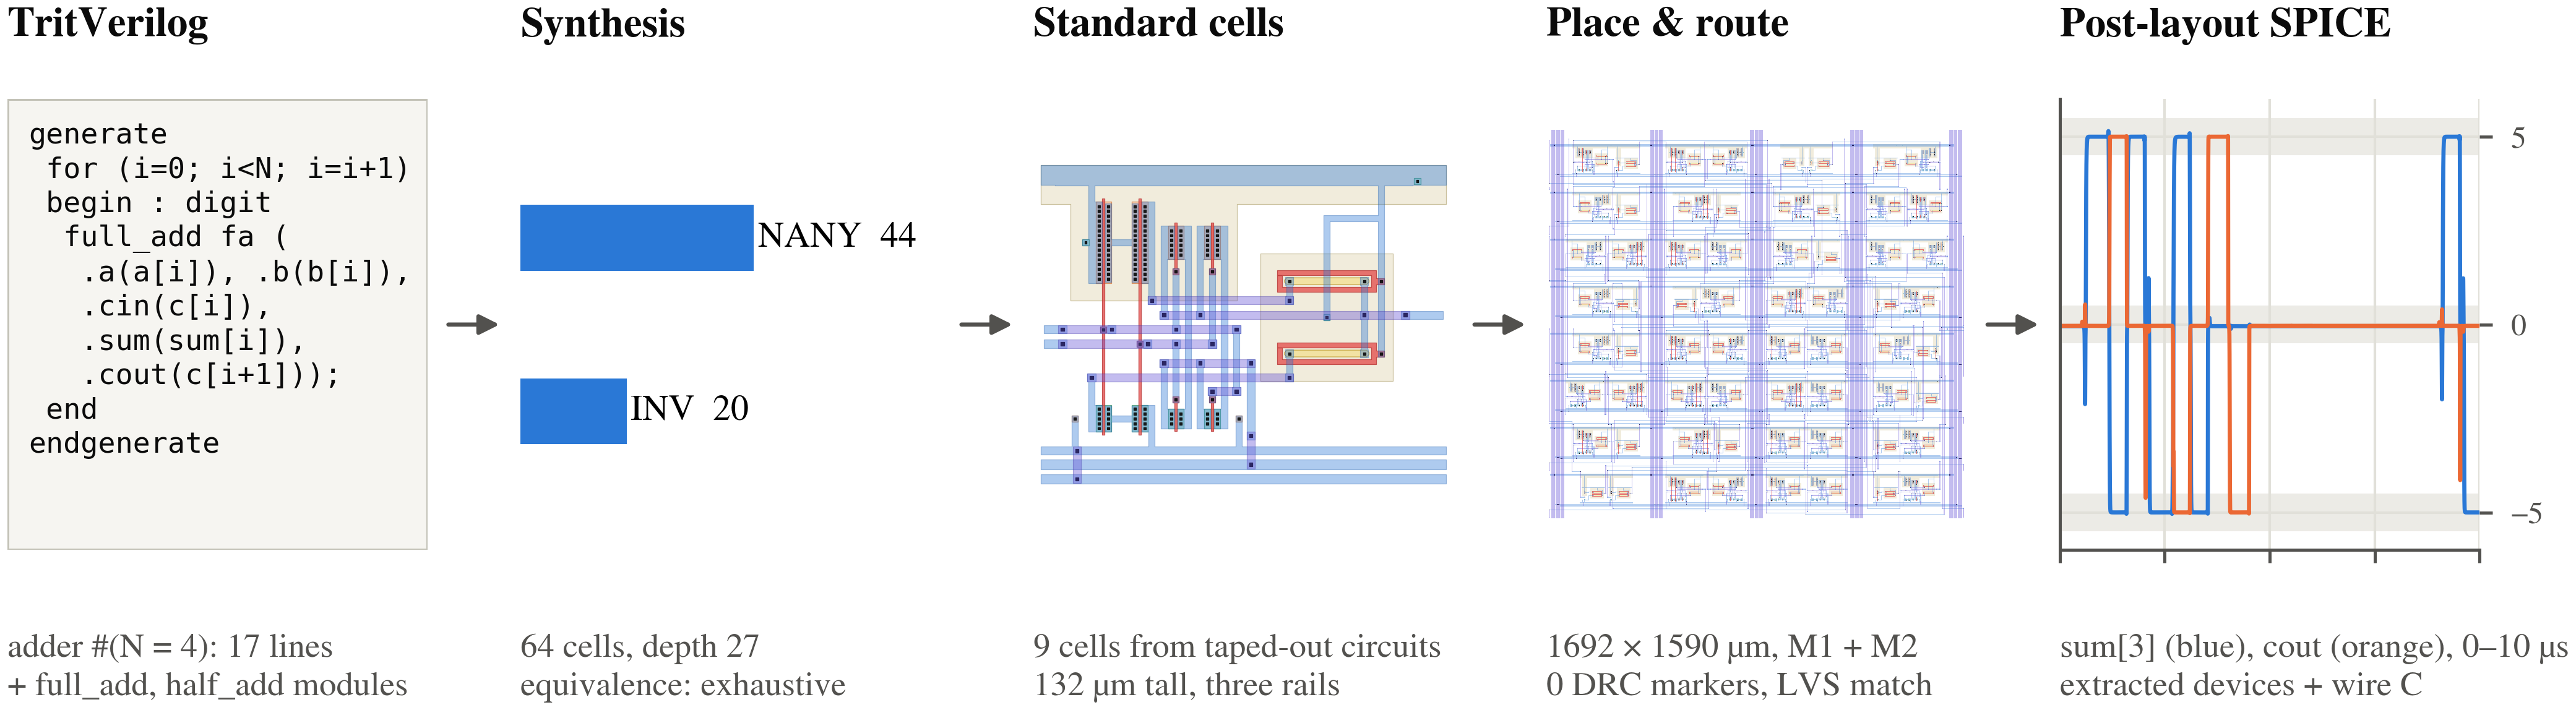

**The illustrated 4-trit adder:** 17 top-level HDL lines plus shared modules → 64 cells, a 1692 × 1590 µm GDS, 0 drawing-DRC markers and LVS Match.

The middle level has a standing cost: 4.17 mW per mapped cell for this adder mix, reaching 0.4 W at 6 trits. Sizing trades current against voltage accuracy.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PenguinEino/tritflow/blob/colab-v0/notebook/tritflow_tr1um.ipynb)

Free Colab verification at [2c81d2c](https://github.com/PenguinEino/tritflow/commit/2c81d2c1aa81ecebefaa93851f004eb17c9040ba): all 18 code cells completed in 405 s on the successful second Run all (initial setup attempt excluded).

If Run all stops after setup, choose Run all again.

<details><summary>Author and license</summary>

- Name: Einosuke Okazaki (岡崎 英之介)
- Affiliation: Information and Communication Engineering Course, Department of Monozukuri
  Engineering, Tokyo Metropolitan College of Industrial Technology (KOSEN), Tokyo, Japan
- Status: Fifth-year student (final year of the five-year KOSEN engineering programme, which
  combines upper-secondary and the first two years of tertiary education)
- Email: einosukeokazaki@gmail.com
- GitHub: PenguinEino

Einosuke Okazaki will attend ISSCC 2027 in person and present the poster if selected (confirmed by the author, 2026-10-18).

Apache-2.0, including historical schematic assets released by their author.

</details>


In [2]:
_TRITFLOW_SETUP_READY = False
globals().pop("_tf_cells", None)
import os, sys, json, time, hashlib, subprocess, importlib.util
from pathlib import Path
started = time.monotonic()
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
SOURCE_URL = "https://github.com/PenguinEino/tritflow.git"
SOURCE_REF = os.environ.get("TRITFLOW_REF", "colab-v0")
def source_git(*args):
    return subprocess.check_output(["git", "-C", str(ROOT), *args], text=True).strip()
if IN_COLAB:
    ROOT = Path("/content/tritflow")
    if not SOURCE_REF or SOURCE_REF.startswith("-") or any(c.isspace() for c in SOURCE_REF):
        raise ValueError("TRITFLOW_REF must name a Git tag or branch")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--single-branch", "--branch", SOURCE_REF,
                        SOURCE_URL, str(ROOT)], check=True)
    if not (ROOT/".git").is_dir():
        raise RuntimeError("/content/tritflow must be a git clone; use a fresh Colab runtime")
    if source_git("remote", "get-url", "origin").removesuffix(".git") != SOURCE_URL.removesuffix(".git"):
        raise RuntimeError("existing checkout has a different origin; use a fresh Colab runtime")
    SOURCE_COMMIT = source_git("rev-parse", "--verify", "HEAD^{commit}")
    requested_commit = source_git("rev-parse", "--verify", SOURCE_REF+"^{commit}")
    if SOURCE_COMMIT != requested_commit or source_git("status", "--porcelain", "--untracked-files=no"):
        raise RuntimeError("existing checkout differs from TRITFLOW_REF; use a fresh Colab runtime")
    print(f"Source: {SOURCE_URL} ref={SOURCE_REF} commit={SOURCE_COMMIT}", flush=True)
    if not (ROOT/"notebook/runtime_support.py").is_file():
        raise RuntimeError("TRITFLOW_REF predates this notebook's setup. Select its matching immutable release with TRITFLOW_REF in a fresh runtime.")
    sys.path.insert(0, str(ROOT/"notebook"))
    from runtime_support import SETUP_SCHEMA
    runtime = ROOT/"notebook/runtime.json"
    if not runtime.is_file() or json.loads(runtime.read_text()).get("TRITFLOW_SETUP_SCHEMA") != SETUP_SCHEMA:
        subprocess.run(["bash", str(ROOT/"notebook/colab_setup.sh"), "--source", str(ROOT)], check=True)
    os.environ.update(json.loads(runtime.read_text()))
else:
    candidates = [Path(os.environ.get("TRITFLOW_ROOT", ".")), Path.cwd(), Path.cwd().parent]
    ROOT = next((p.resolve() for p in candidates if (p/"pyproject.toml").is_file()
                 and (p/"tritflow").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("run locally from the full checkout or set TRITFLOW_ROOT")
    SOURCE_COMMIT = source_git("rev-parse", "--verify", "HEAD^{commit}") if (ROOT/".git").exists() else "tracked-tree export (no .git)"
    print(f"Source: {ROOT} commit={SOURCE_COMMIT}")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/"notebook"))
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
from runtime_support import check_runtime, print_tool_versions
check_runtime()
print_tool_versions()
_TRITFLOW_SETUP_READY = True


Source: $TRITFLOW_ROOT commit=06af81134cd256b36a3c7709a8cebecf34230412
Scientific Python (host versions preserved): numpy=2.4.3, scipy=1.17.1, matplotlib=3.10.8, plotly=7.1.0


KLayout executable: /home/ishi-kai/bin/klayout/klayout
KLayout 0.30.9
ngspice executable: /usr/local/bin/ngspice
******
** ngspice-46+ : Circuit level simulation program
** Compiled with KLU Direct Linear Solver
** The U. C. Berkeley CAD Group
** Copyright 1985-1994, Regents of the University of California.
** Copyright 2001-2025, The ngspice team.
** Please get your ngspice manual from https://ngspice.sourceforge.io/docs.html
** Please file your bug-reports at http://ngspice.sourceforge.net/bugrep.html
** Creation Date: Fri May 29 07:44:23 UTC 2026
******


In [3]:
NARRATIVE_CONTEXT_SHA256 = 'd9572a34d1b3565d8c3a5d49ad8fbf4fb999743265871b3dda0d574e3758e72c'

globals().pop("_tf_cells", None)
if not globals().get("_TRITFLOW_SETUP_READY", False):
    raise RuntimeError("Run the first setup cell successfully, then rerun the imports cell. If setup requested a restart, restart once first.")
from runtime_support import CellState
import numpy as np
from IPython.display import display, HTML, Image
from tritflow import flow, CELLS_DIR, PDK_ROOT, PASS_BAND, TRIT_VOLTS
from tritflow.sim import dc_transfer, input_vectors, subcircuits
from tritflow.viz.graph import truth_table_html
from tritflow.viz.waves import waveform_figure
from tritflow.viz.layout import render_gds, placement_animation, routing_progress
from tritflow.viz.cell import device_mapping
from tritflow.sim.provenance import pdk_provenance
from tritflow.sim.postlayout import logical_nodeset
from cache import Cache, runtime_fingerprint, source_manifest
from campaign import RecordedCampaign
from schematics import schematic_gallery
from experiments import (complete_design, experiment_artifacts, assert_experiment,
                         load_edited, verify_publication_sources, adder_demo_vectors)
EXTENDED = os.environ.get("TRITFLOW_EXTENDED", "0") == "1"
BUILD = Path(os.environ.get("TRITFLOW_NOTEBOOK_BUILD", ROOT/"build/notebook")).resolve()
qualified_pdk = pdk_provenance(PDK_ROOT)
assert qualified_pdk["qualified_commit"] == json.loads((ROOT/"notebook/setup_pins.json").read_text())["pdk_commit"]
native_sources = source_manifest(ROOT,PDK_ROOT)
cache = Cache(BUILD/"cache", runtime_fingerprint(ROOT, PDK_ROOT,names=native_sources),
              force=os.environ.get("TRITFLOW_FORCE_RUN", "0") == "1",sources=native_sources)
recorded_campaign = RecordedCampaign(ROOT/"notebook/assets/four_designs.zip",ROOT,PDK_ROOT,
                                     enabled=not cache.force)
renderer_sha256 = hashlib.sha256((ROOT/"tritflow/viz/layout.py").read_bytes()).hexdigest()
from presentation import show, table, evidence

from IPython.display import Markdown, Code
from editorial import context, context_identity, render as render_narrative, dimensions
from paper_evidence import load_paper
from learning import sizing_slider, value_selector
from predictions import divider, zero_dc, rail_power
from presentation import details_html, details_svg
from routing_identity import routing_label, archive_routing
paper = load_paper(ROOT)
narrative_values = context(ROOT)
assert context_identity(narrative_values) == NARRATIVE_CONTEXT_SHA256, "Published figure measurements changed; regenerate the notebook before running."

_tf_cells = CellState({'setup': 'setup', 'imports': 'imports', 'opening': 'Chapter 0: From HDL to a checked adder layout', 'gates': '1. Three levels from ordinary CMOS', 'sizing': '2. Sizing sets the middle level', 'cells': '3. Taped-out circuits become placeable cells', 'arithmetic': '4. Describe signed arithmetic in TritVerilog', 'synthesis': '5. Follow an expression into cells', 'schematic': '5. Follow an expression into cells', 'pnr': '6. Route signals and feed the standing current', 'pre': 'Chapter 7: Does the layout still work?', 'published': 'Chapter 7: Does the layout still work?', 'edit': 'Chapter 8: Change the circuit and close the loop', 'custom': 'Chapter 8: Change the circuit and close the loop', 'broken': 'Chapter 8: Change the circuit and close the loop', 'characterization': 'Appendix B: Verification evidence and how to rerun', 'four': 'Appendix B: Verification evidence and how to rerun', 'final': 'Appendix B: Verification evidence and how to rerun'})


## 0. From HDL to a checked adder layout

The paper figure shows a 4-trit ripple adder; the executable
example builds a 2-trit version. Run the short API chain, then
inspect the generated layout and the most significant sum digit and carry.

A trit takes the values −1, 0 and +1. Here their voltages are
-5, 0 and +5 V. A trit is a
signal type of its own; Verilog's `x` and `z` are not extra trit values.
The waveform's shaded bands show the allowed error around each target level.

> **What this shows.** The HDL, mapped cells, extracted connections and
> waveforms describe the same arithmetic. The shaded voltage bands connect
> each signed output trit to its physical acceptance check.

Next, we open one of those cells and explain how it makes the middle voltage.


```python
d = flow.load("examples/adder.tv", "adder", {"N": 2})
net = d.synthesize()
lay = net.place_and_route()
assert lay.drc()["clean"] and lay.lvs()["matched"]
post = lay.extract().simulate(vectors, load=LOAD_F)
```


In [4]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('opening', 'Chapter 0: From HDL to a checked adder layout', requires=[]):
    d = flow.load(ROOT/"examples/adder.tv", "adder", {"N": 2})
    net = d.synthesize(name="adder2_demo")
    logical = d.truth_table()
    inputs = [p.name for p in net.ports if p.dir == "input"]
    outputs = [p.name for p in net.ports if p.dir == "output"]
    vectors, vector_labels = adder_demo_vectors(inputs)
    LOAD_F, HOLD_S, STEP_S, EDGE_S, TEMP_C = 100e-15, 1e-6, 2e-9, 1e-9, 27
    PNR_ROWS, PNR_ANNEAL_STEPS = None, 600  # automatic near-square floorplan; placement effort
    assert all(len(v) == len(inputs) for v in vectors)
    assert len(logical[inputs[0]]) == 3**len(inputs)
    def adder_reference(vector):
        v = dict(zip(inputs, vector, strict=True))
        remainder = sum((v[f"a[{i}]"] + v[f"b[{i}]"])*3**i for i in range(2)) + v["cin"]
        result = {}
        for i in range(2):
            result[f"sum[{i}]"] = (remainder+1)%3-1
            remainder = (remainder-result[f"sum[{i}]"])//3
        return {**result, "cout": remainder}
    expected_sequence = [adder_reference(v) for v in vectors]
    assert all({r[p] for r in expected_sequence} == {-1,0,1} for p in outputs)
    assert all(a != b for a,b in zip(vectors,vectors[1:]))
    for row in zip(*(logical[name] for name in inputs)):
        assert adder_reference(row) == {k: int(v) for k,v in d.design.evaluate(dict(zip(inputs,row))).items()}
    out = BUILD/"adder2_demo"
    def complete_adder():
        lay = net.place_and_route(output_dir=out, seed=0, rows=PNR_ROWS, anneal_steps=PNR_ANNEAL_STEPS)
        drc = lay.data["checks"]["pdk_drc"]  # actual official deck report just produced by PNR
        lvs = lay.lvs()
        assert drc["clean"] and lvs["matched"], (drc, lvs)
        extracted = lay.extract()
        guesses = logical_nodeset(net,lvs["report"],inputs,vectors[0])
        post = extracted.simulate(vectors, load=LOAD_F, hold_s=HOLD_S, step_s=STEP_S, edge_s=EDGE_S,
                                  temperature_c=TEMP_C, expected=adder_reference, nodeset=guesses,
                                  timeout=600, workdir=out/"post")
        assert post["measurements"]["passed"], post["measurements"]
        return {**post, "stats": lay.stats, "drc": drc, "lvs": lvs,
                "extracted_spice": extracted.spice, "capacitance": extracted.capacitance,
                "initial_nodeset_v":guesses}
    demo = cache.run("adder2-complete", {"net": net.to_json(), "vectors": vectors, "load": LOAD_F,
                                       "hold": HOLD_S, "step": STEP_S, "edge": EDGE_S,
                                       "temperature_c":TEMP_C, "seed": 0,
                                       "rows":PNR_ROWS,"anneal_steps":PNR_ANNEAL_STEPS}, complete_adder,
        artifacts=lambda r: [out/"adder2_demo.gds", out/"adder2_demo.pnr.json",
                             r["drc"]["report_path"], r["lvs"]["report"], r["lvs"]["extracted"]])
    lay = flow.load_layout(net, out)
    assert demo["drc"]["clean"] and demo["lvs"]["matched"] and demo["measurements"]["passed"]
    assert not lay.stats["library_mock"]
    assert all({row["outputs"][p]["ideal_trit"] for row in demo["measurements"]["rows"]} == {-1,0,1}
               and demo["measurements"]["max_settling_s"][p] > 0 for p in outputs)

    table([["Live adder", "Cells", "Die (µm)", "DRC markers", "Strict LVS", "Analog"],
           [net.top,net.report()["total_cells"],dimensions(lay.stats["die_size_um"]),
            demo["drc"]["violations"],demo["lvs"]["matched"],demo["measurements"]["passed"]]])
    print(f"Independent integer oracle: {len(logical[inputs[0]])} exhaustive states; extracted sequence: {len(set(vectors))} selected states.")


Running: adder2-complete


Live adder,Cells,Die (µm),DRC markers,Strict LVS,Analog
adder2_demo,32,1284 × 1038,0,True,True


Independent integer oracle: 243 exhaustive states; extracted sequence: 9 selected states.


## 1. Three levels from ordinary CMOS

The middle output level comes from conducting transistor and resistor branches.
At a zero input, the inverter connects its output toward both supply rails;
the balance sets the voltage and draws current even with constant inputs.
NANY adds paths to VMID that clamp the output for opposite input trits.
Read each transfer curve above its VDD current, with the other input held
at each logical level.

The gate functions are

$$
\begin{aligned}
\mathrm{INV}(a)&=-a, & \mathrm{NAND}(a,b)&=-\min(a,b),\\
\mathrm{NOR}(a,b)&=-\max(a,b), & \mathrm{NANY}(a,b)&=-\mathrm{clamp}(a+b,-1,1).
\end{aligned}
$$

**Predict first.** Select INV and set its input to the middle voltage. Replace
each conducting MOS with an on-resistance and keep the series resistors.
Call the complete upper and lower branch resistances $R_u$ and $R_d$.

$$
I_{\mathrm{hand}}=\frac{V_{DD}-V_{SS}}{R_u+R_d},\qquad
V_{Y,\mathrm{hand}}=V_{SS}+I_{\mathrm{hand}}R_d,
$$

$$
P_{\mathrm{hand}}=(V_{DD}-V_{SS})I_{\mathrm{hand}}.
$$

Equal branch resistances predict the middle voltage. The displayed estimate
uses device dimensions and the PDK's nominal model parameters; SPICE then
includes the nonlinear devices.


At A=VMID the possible conducting path is VDD → MP → RP → Y → RN → MN → VSS. The nominal dimensions give $R_u$ = 11.33 kΩ and $R_d$ = 11.23 kΩ. **Hand estimate, before SPICE:** I = 0.4432 mA; Y = -0.02066 V; P = 4.432 mW.



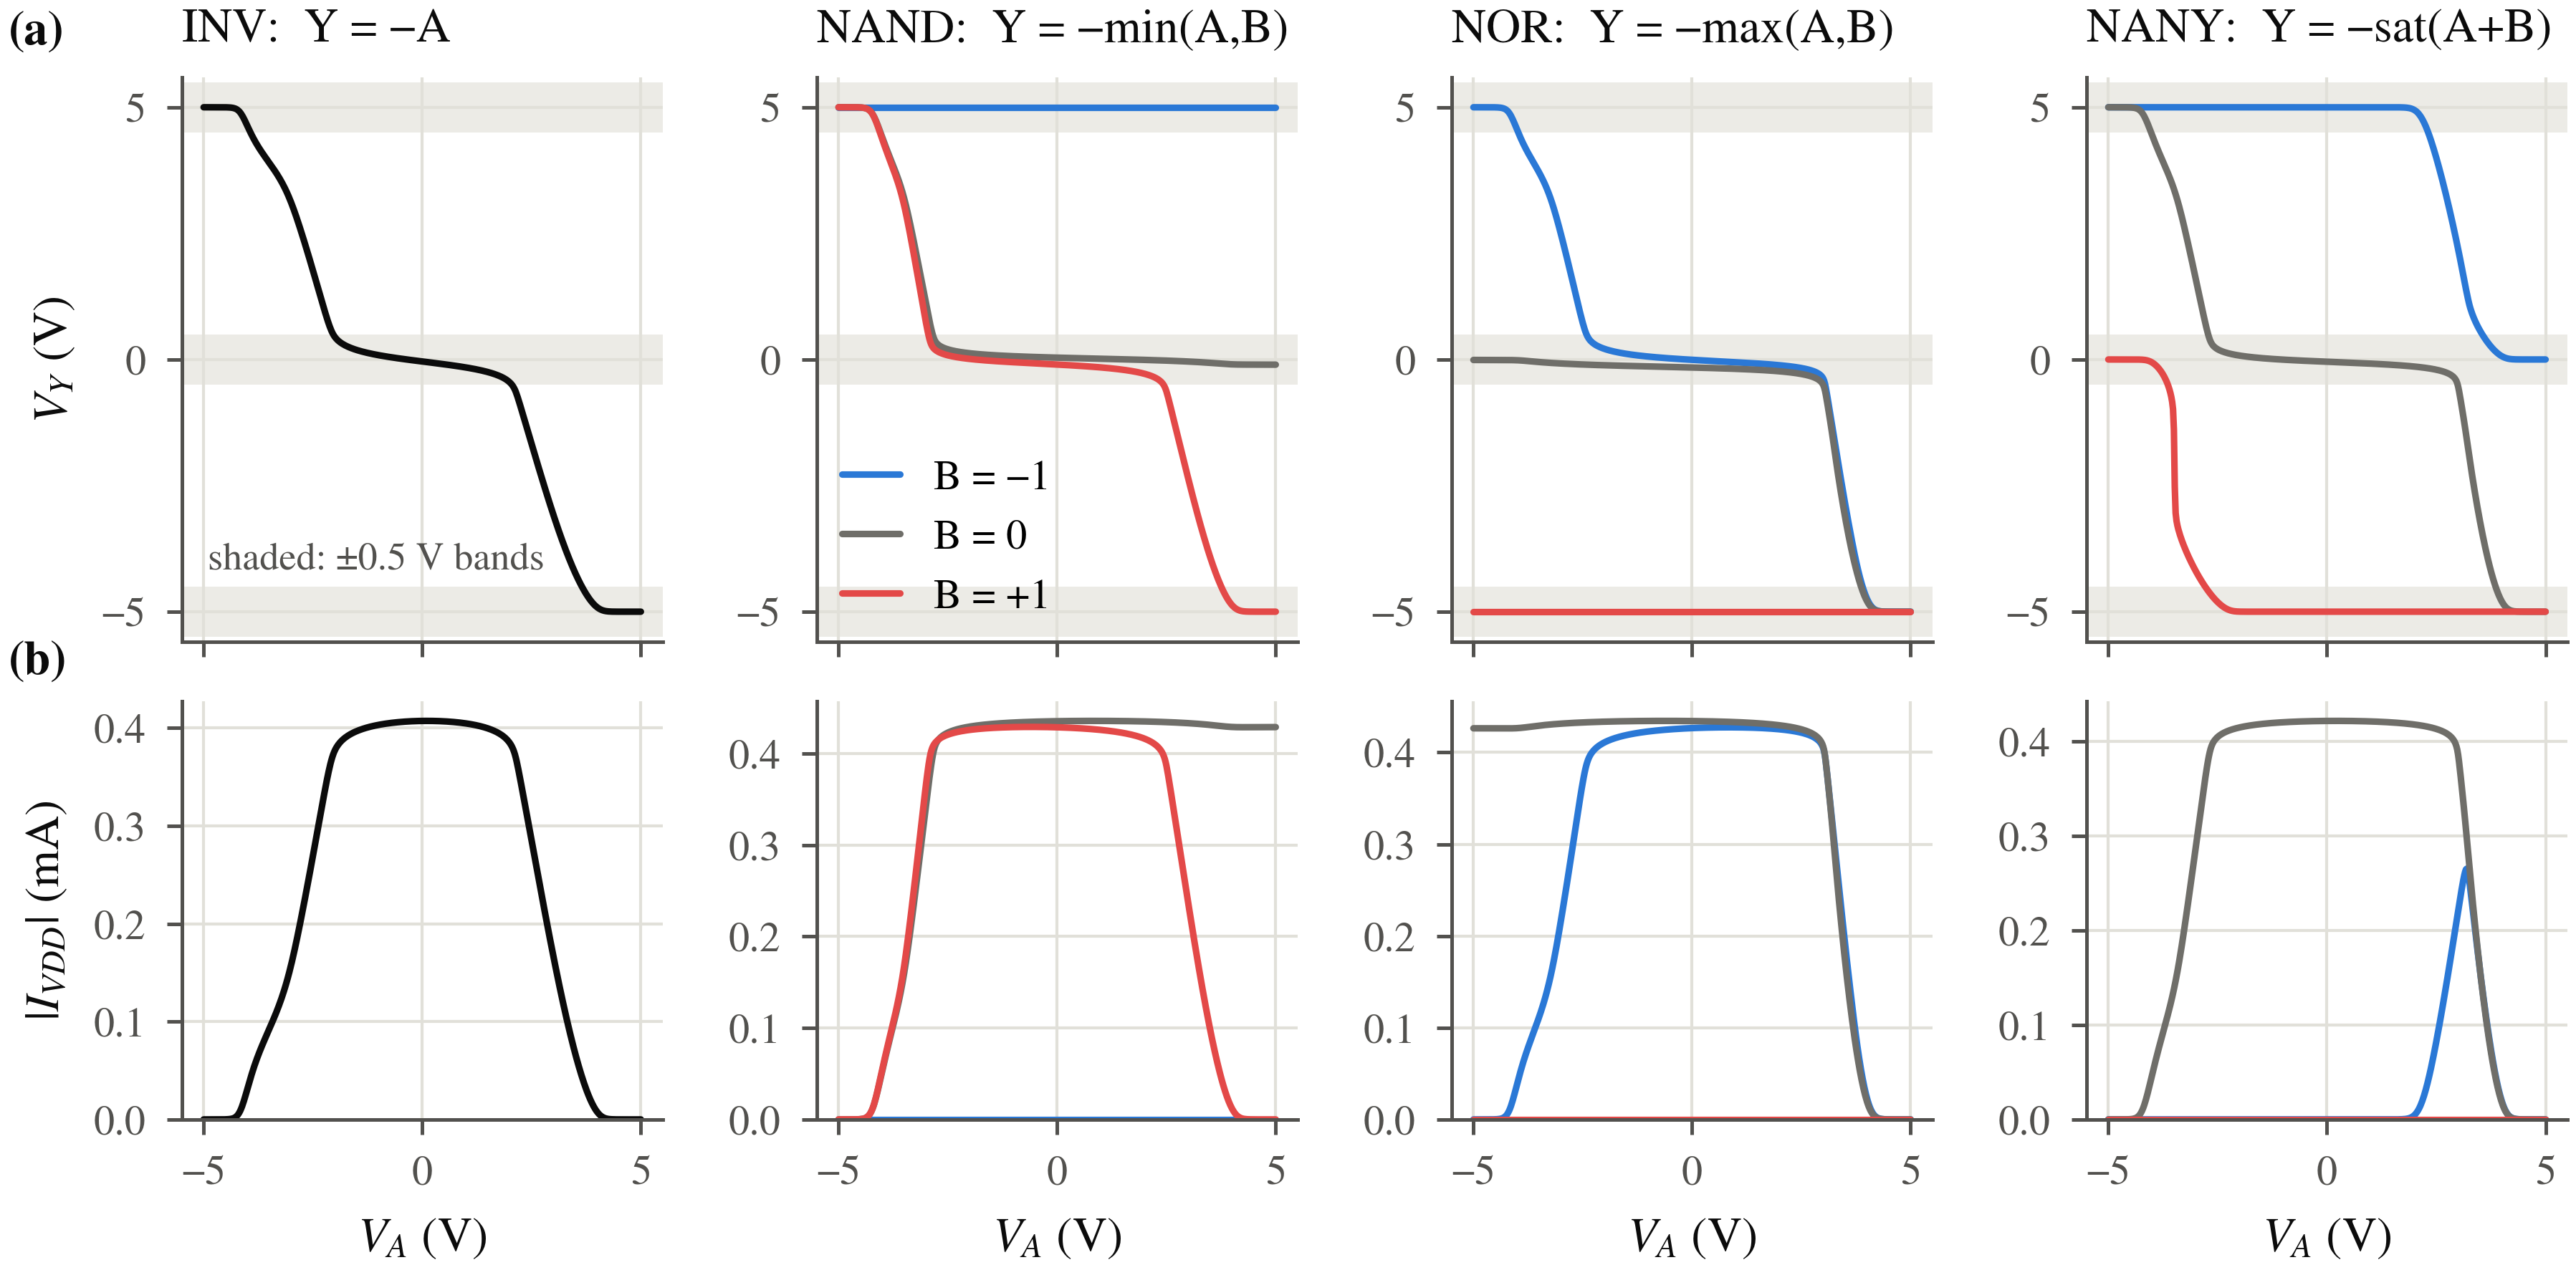

**DC behavior of the ternary logic cells** (a) Output voltage and (b) absolute
VDD current versus input A for the extracted INV, NAND, NOR and NANY cells at
27 °C, with B held at each trit level where applicable.
At its middle input, INV draws 0.4072 mA from VDD,
corresponding to 4.072 mW of signed total rail power;
shading marks the ±0.5 V output acceptance bands.

> **What this shows.** At a middle input, the extracted INV settles at
> -0.03954 V and draws 0.4072 mA from
> VDD at 27 °C. Its signed rail powers sum to
> 4.072 mW with constant input.

The schematic-dimension divider estimate gives -0.02066 V and
4.432 mW, compared with -0.03954 V and
4.072 mW in the matching schematic DC calculation.

At $a=0$, both $\min(a,-a)$ and $\max(a,-a)$ equal zero.
That example is enough to reject Boolean complementation as a synthesis rule.


Vector,ainput,binput,invaoutput,nandaboutput,noraboutput,nanyaboutput
1,-1,-1,+1,+1,+1,+1
2,-1,0,+1,+1,0,+1
3,-1,+1,+1,+1,-1,0
4,0,-1,0,+1,0,+1
5,0,0,0,0,0,0
6,0,+1,0,0,-1,-1
7,+1,-1,-1,+1,-1,0
8,+1,0,-1,0,-1,-1
9,+1,+1,-1,-1,-1,-1


Running: inv-dc


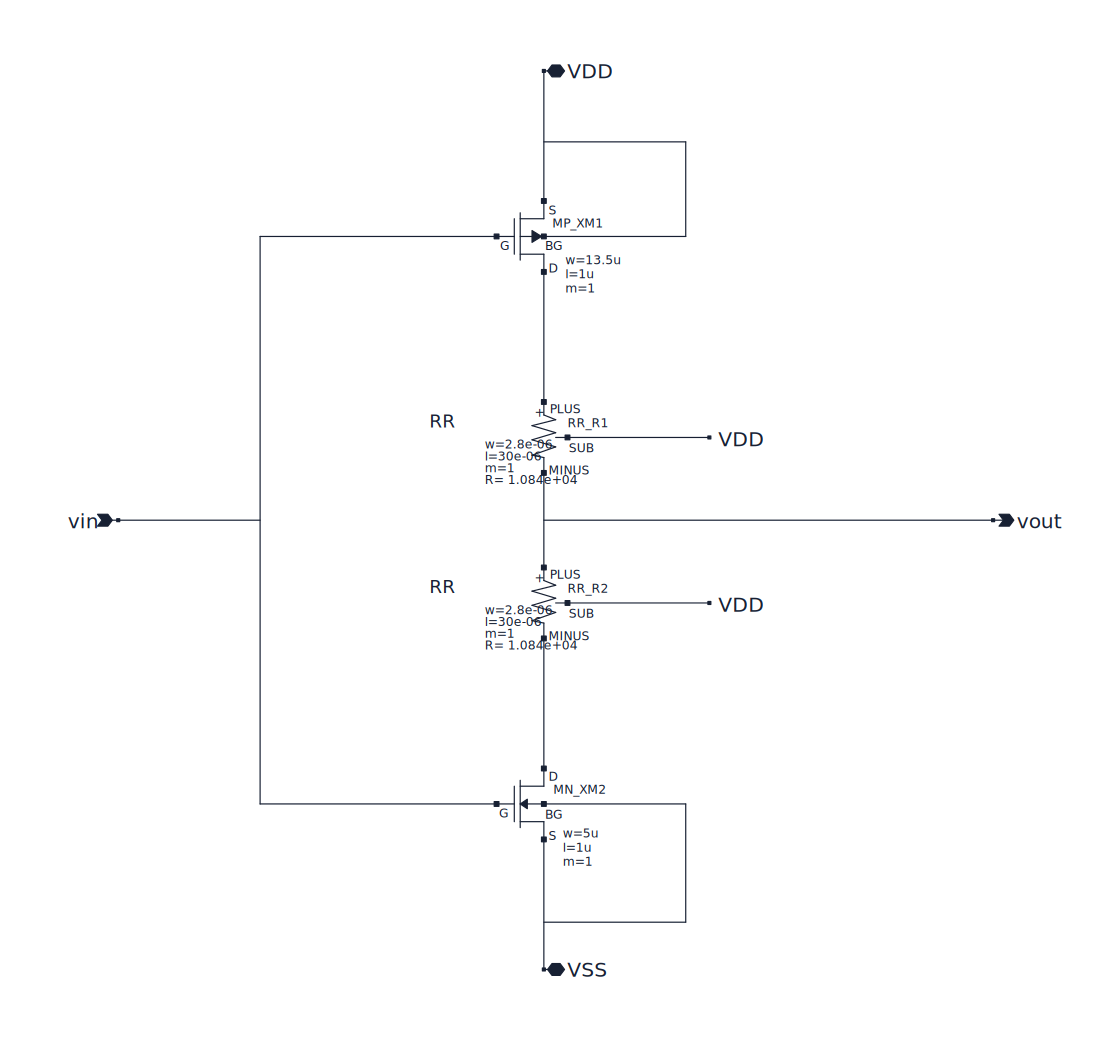

In [5]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('gates', '1. Three levels from ordinary CMOS', requires=[]):
    gates = flow.loads("""module gates(input trit a,b,output trit inva,nandab,norab,nanyab);
     assign inva=~a; assign nandab=~(a&b); assign norab=~(a|b); assign nanyab=nany(a,b);
     endmodule""")
    t = gates.truth_table()
    assert np.array_equal(t["inva"], -t["a"])
    assert np.array_equal(t["nandab"], -np.minimum(t["a"], t["b"]))
    assert np.array_equal(t["norab"], -np.maximum(t["a"], t["b"]))
    assert np.array_equal(t["nanyab"], -np.clip(t["a"]+t["b"],-1,1))

    details_html("Gate truth tables", truth_table_html(gates.design))
    for name in ["INV","NAND","NOR","NANY"]:
        body = subcircuits((CELLS_DIR/f"out/{name}/{name}.spice").read_text())[name.lower()]["body"]
        assert ("VMID" in body.upper()) == (name == "NANY"), name
    # Same public DC call and zero-input sample as the static gate figure.
    curve = cache.run("inv-dc", {"step_v":.02},lambda:
        dc_transfer((CELLS_DIR/"out/INV/INV.ext.spice").read_text(),"INV",["A"],["Y"],"A",
                    fixed_trits={},step_v=.02))
    i = int(np.argmin(abs(curve["data"]["v-sweep"])))
    assert abs(curve["data"]["v-sweep"][i]) < 1e-9
    assert abs(curve["data"]["v(y)"][i]-paper["inv_dc"]["output_v"]) < 1e-8
    details_html("Taped-out INV schematic and exported source",schematic_gallery(
        ROOT/"notebook/assets/schematics",names=["INV"],selected="INV"))


## 2. Sizing sets the middle level

Sizing changes both sides of the divider. A stronger pull-down lowers the
middle output; a stronger pull-up raises it. Increasing both series resistors
reduces static current, while MOS asymmetry still affects the voltage.
Compare inverter transfer curves at fixed MOS sizes, then read the error/current
scatter plots for INV and NANY. The circled points mark the adopted reference
dimensions.

**Predict first.** For the conducting MOS devices, take on-resistance as
inversely proportional to $W/L$. Apply the divider from the previous chapter
before looking at the new SPICE curve.

$$
r_{\mathrm{on}}'\simeq r_{\mathrm{on}}
\frac{(W/L)_{\mathrm{adopted}}}{(W/L)'},\qquad
I'=\frac{V_{DD}-V_{SS}}{R_u'+R_d'},
$$

$$
\Delta V_Y\simeq
(V_{DD}-V_{SS})\frac{R_u\Delta R_d-R_d\Delta R_u}{(R_u+R_d)^2}.
$$



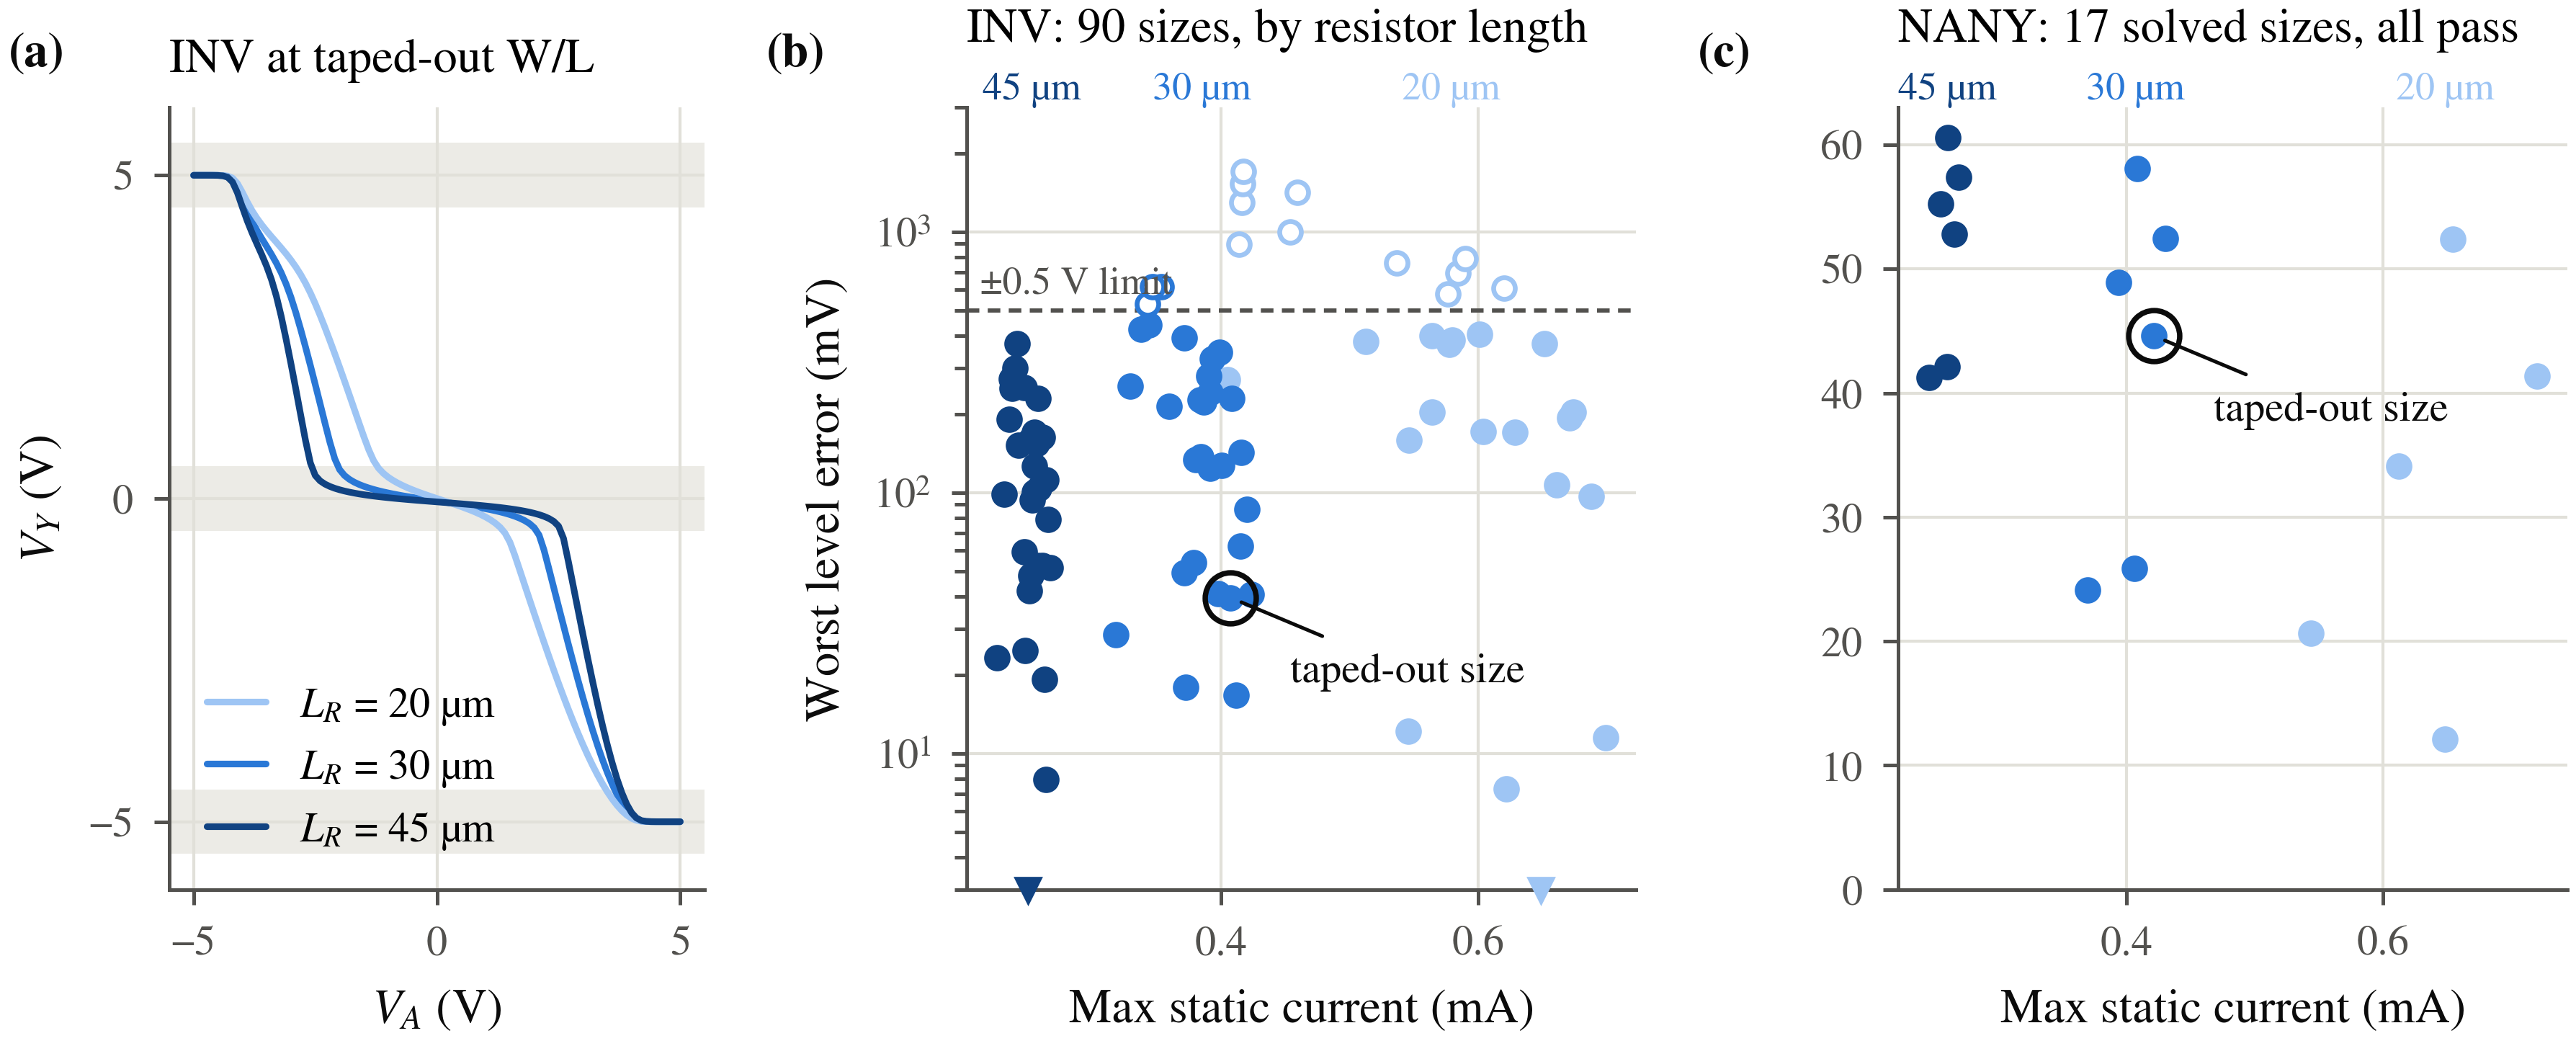

**Dimensions control middle-level accuracy and standing current** (a) INV
transfer curves for resistor lengths 20, 30, 45 µm
at the adopted MOS dimensions; (b,c) worst discrete-state level error versus
maximum absolute rail current for 90 finite INV and
17 finite NANY results.
Filled and open markers distinguish errors within and outside
±0.5 V, inverted triangles place errors below
3 mV at the display floor, and outer rings identify
the dimensions used in the reference design.

> **What this shows.** The scatter plots contain 90
> finite INV results and 17 finite NANY results.
> At the circled INV size, worst logical level error is
> 39.54 mV and maximum absolute rail current is
> 407.2 µA; the corresponding NANY values are
> 44.6 mV and 421.4 µA.

Lengthening both INV resistors from 30 to
45 µm at fixed MOS dimensions, the divider predicts an
upward middle-level shift of 7.984 mV; schematic SPICE
instead gives -12.9 mV. The hand model gets the reduction
in current right, but misses the sign of this small voltage shift. It keeps
only geometric resistor resistance and a constant MOS on-resistance. Both
F_RR substrate terminals actually tie to VDD, while the two resistors' signal
terminals sit at different voltages, so their bias-dependent resistance
corrections differ; the MOS also operate nonlinearly. The measured trade-off
is current falling from 407.2 to
260.7 µA while worst level error rises from
39.54 to 52.44 mV.


INV at zero input,Hand,Matching schematic SPICE
Output (V),-0.02066,-0.03954
Static power (mW),4.432,4.072


Common RR length (µm),Worst level error (mV),Max |rail I| (µA),Reference
20,0.06736,649,
30,39.54,407.2,taped out
45,52.44,260.7,


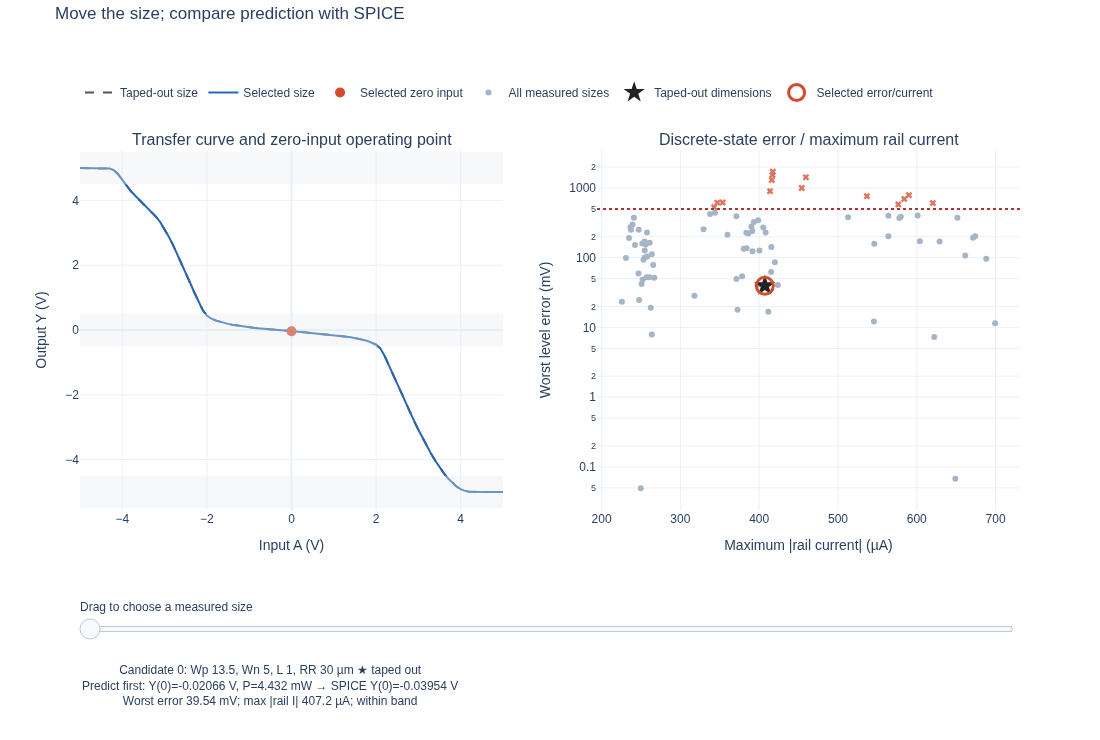

In [6]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('sizing', '2. Sizing sets the middle level', requires=[]):
    from tritflow.sim.sizing import load_grid
    sizing_grids = {cell:load_grid(cell) for cell in ("INV","NANY")}
    gi = sizing_grids["INV"]
    adopted = gi["rows"][gi["adopted_index"]]
    hand = divider(adopted["dimensions"],PDK_ROOT)
    table([["INV at zero input", "Hand", "Matching schematic SPICE"],
           ["Output (V)",hand["output_v"],zero_dc(adopted)["output_v"]["Y"]],
           ["Static power (mW)",hand["power_w"]*1e3,
            rail_power(zero_dc(adopted),gi["conditions"]["supplies_v"])*1e3]])
    # Hold MOS sizes fixed: these are actual simulated RR candidates.
    rr_candidates = sorted((r for r in gi["rows"] if r["dc"] and
        all(r["dimensions"][k] == adopted["dimensions"][k] for k in ("MP","MN"))),
        key=lambda r:r["dimensions"]["RP"]["l_um"])
    table([["Common RR length (µm)","Worst level error (mV)","Max |rail I| (µA)","Reference"]]+[
        [r["dimensions"]["RP"]["l_um"],r["max_error_v"]*1e3,r["max_static_current_a"]*1e6,
         "taped out" if r["is_adopted"] else ""] for r in rr_candidates])
    show(sizing_slider(gi,PDK_ROOT))


## 3. Taped-out circuits become placeable cells

A router needs a cell boundary, legal pin landings and obstacles as well as
a circuit. These cells share a height and carry VDD, VMID and VSS horizontally
across the row. Compare the original and adapted NANY at the same scale, then
follow each rail across the abutted row. Device outlines identify the pull-up,
pull-down, clamp and resistor groups.

Internal M2 and vias appear in the routing obstacles. Signal pins sit on M1
where a vertical M2 route can reach them through a via. Cells may face forward
or reflect left to right while preserving the rail order. TIE cells supply
constants through finite resistance; FILL continues rails and wells through gaps.



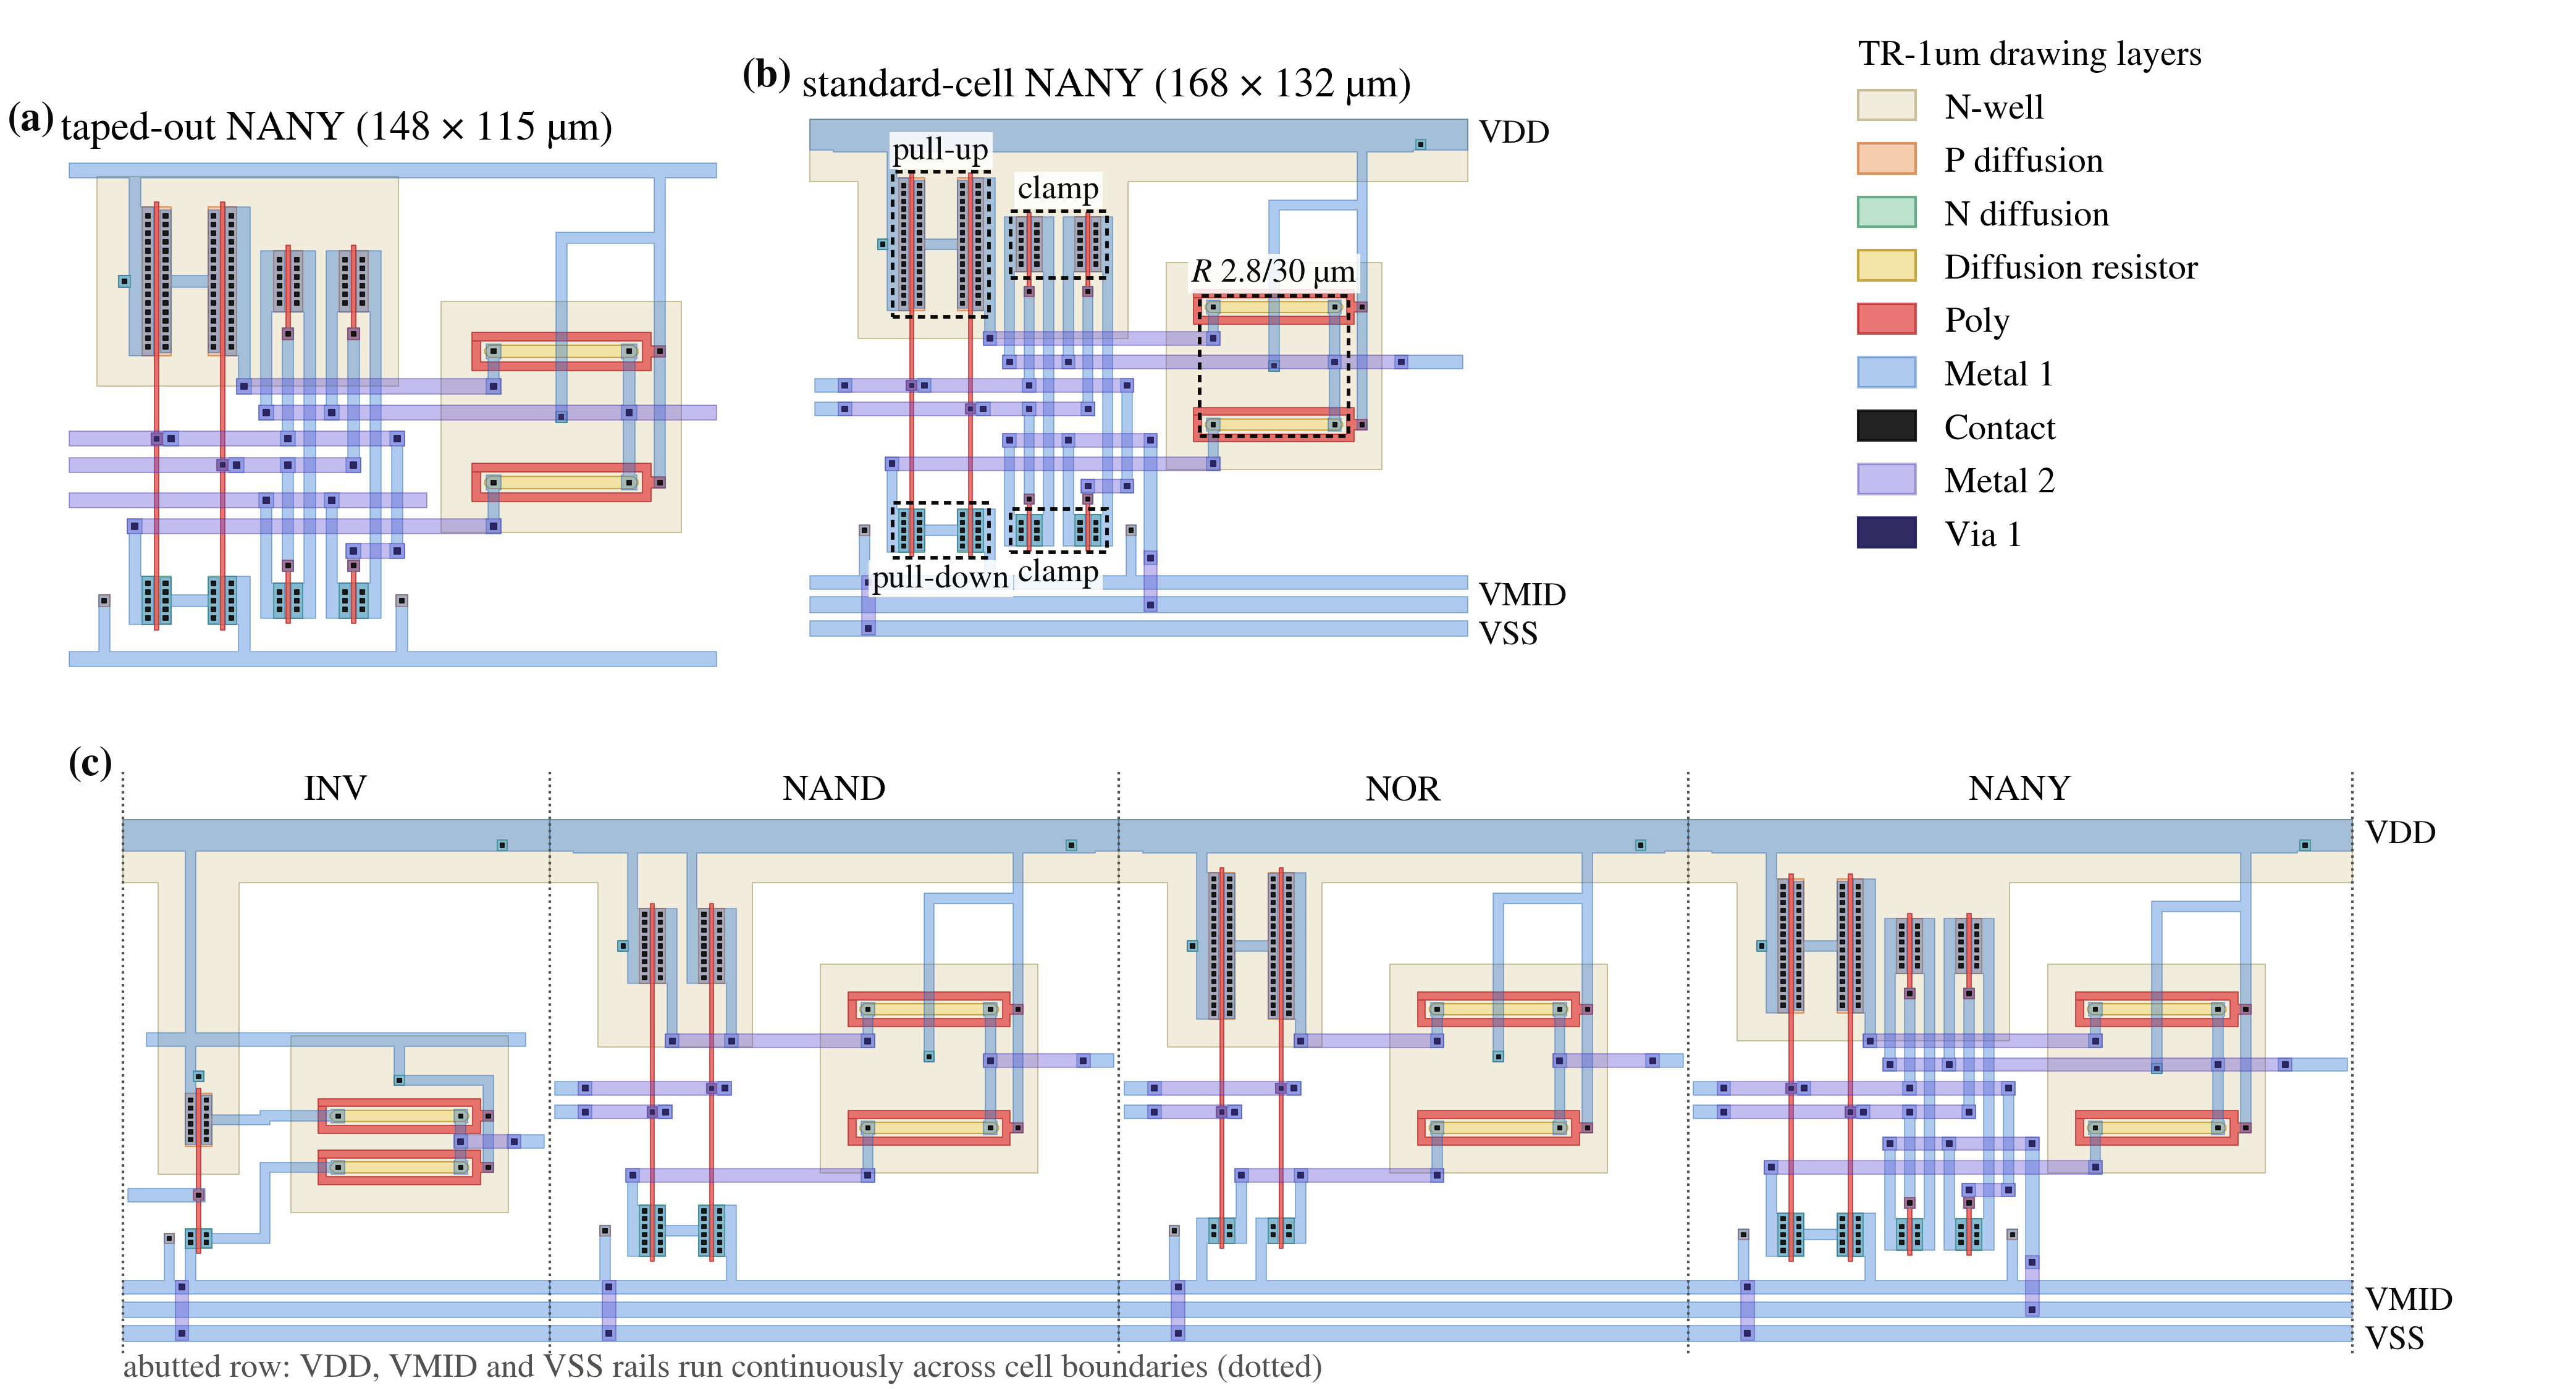

**Adapting the reference NANY to a three-rail cell row** (a) The taped-out
reference layout occupies 148 × 115 µm; (b) the adapted
cell retains its circuit and device sizes in a 168 ×
132 µm footprint, with the device groups and supply rails labelled.
(c) An abutted row of 4 logic cells carries VDD, VMID
and VSS continuously across the indicated cell boundaries.

> **What this shows.** NANY grows from 148 × 115 µm to
> 168 × 132 µm, or 1.303 times the
> reference footprint, while retaining its circuit and device sizes.
> VDD, VMID and VSS continue across all 4 cells in the row.

The cell checks and row-abutment results are available in Appendix B.


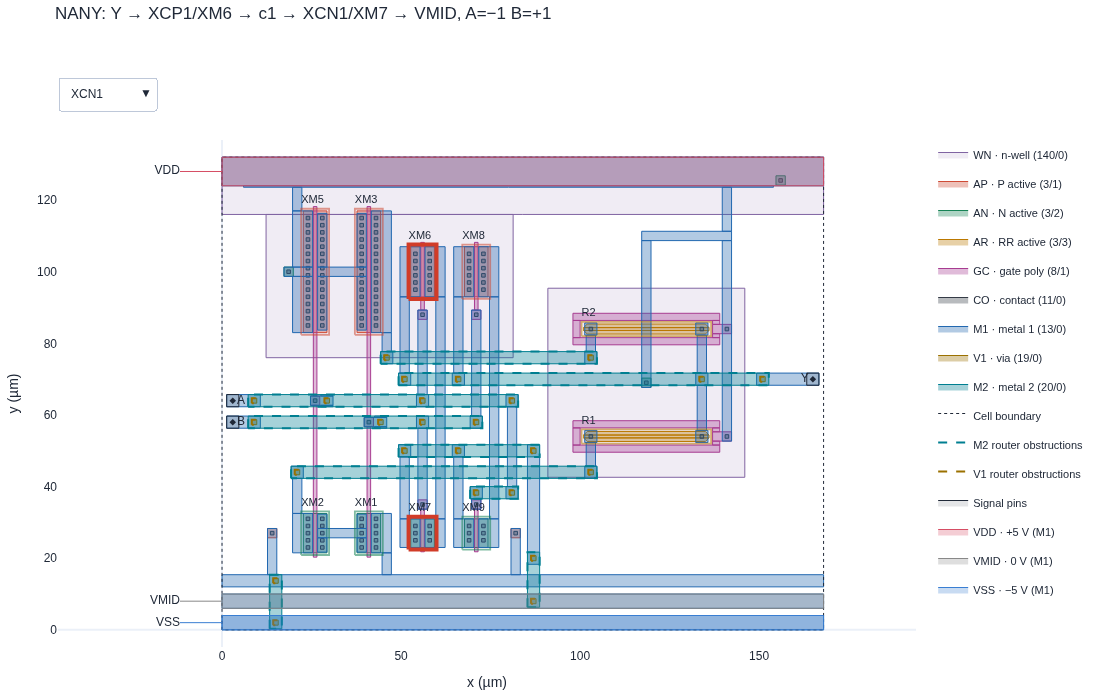

In [7]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('cells', '3. Taped-out circuits become placeable cells', requires=[]):
    template = json.loads((CELLS_DIR/"template.json").read_text())
    generation = json.loads((CELLS_DIR/"out/generation.json").read_text())
    abstracts = {item["name"]:json.loads((CELLS_DIR/"out"/item["abstract"]).read_text())
                 for item in json.loads((CELLS_DIR/"out/library.json").read_text())}
    assert {a["height"] for a in abstracts.values()} == {template["height"]}
    assert generation["height_um"] == template["height"]

    cell_dimension_rows = ([["Cell", "Width × common height (µm)", "Area (µm²)", "Free full-height M2 tracks"]]+
          [[name, [a["width"],a["height"]], a["width"]*a["height"], a["free_M2_tracks"]["count"]]
           for name,a in abstracts.items()])
    abstract = json.loads((CELLS_DIR/"out/NANY/NANY.abstract.json").read_text())
    mapping = device_mapping("NANY", selected="XCN1")
    # Highlight both conducting devices of the zero-level clamp. These are device
    # outlines, not an invented extracted current-density or wire-current map.
    clamp_devices = {"XCP1","XCN1"}
    clamp_body = subcircuits((CELLS_DIR/"out/NANY/NANY.spice").read_text())["nany"]["body"]
    clamp_terminals = {fields[0]:fields[1:5] for fields in map(str.split,clamp_body.splitlines()) if fields}
    assert clamp_terminals["XCP1"] == ["c1","A","Y","VDD"]
    assert clamp_terminals["XCN1"] == ["c1","B","VMID","VSS"]
    clamp_character = json.loads((CELLS_DIR/"out/NANY/NANY.char.json").read_text())
    assert hashlib.sha256((CELLS_DIR/"out/NANY/NANY.ext.spice").read_bytes()).hexdigest() == clamp_character["source_sha256"]
    clamp_dc = next(r for r in clamp_character["dc"] if r["input_trits"] == [-1,1])
    assert clamp_dc["passed"] and abs(clamp_dc["output_v"]["Y"]) <= PASS_BAND
    for trace in mapping.figure.data:
        meta = trace.meta or {}
        if meta.get("kind") == "device" and meta.get("device") in clamp_devices:
            trace.update(line={"color":"#d13c28","width":4},opacity=1)
    mapping.figure.update_layout(title="NANY: Y → XCP1/XM6 → c1 → XCN1/XM7 → VMID, A=−1 B=+1")
    assert clamp_devices <= {r["name"] for r in mapping.rows}
    show(mapping.figure)
    evidence("Device correspondence and W/L",mapping.rows)

    qualification = CELLS_DIR/"out/verify_report.json"
    if qualification.is_file():
        report = json.loads(qualification.read_text())
        assert report["passed"]
        assert all(hashlib.sha256((PDK_ROOT/name).read_bytes()).hexdigest() == value
                   for name,value in report["deck_sha256"].items()), "cell qualification uses a different PDK"
        for cell, artifacts in report["artifact_sha256"].items():
            for suffix, expected_hash in artifacts.items():
                assert hashlib.sha256((CELLS_DIR/f"out/{cell}/{cell}.{suffix}").read_bytes()).hexdigest() == expected_hash
        cell_qualification_rows = ([["Cell", "Recorded DRC clean", "Recorded LVS qualification", "LVS method"]]+[
            [name, result["drc"]["passed"], result["lvs"]["passed"],
             result["lvs"].get("method","strict device/port comparison")]
            for name,result in report["cells"].items()])
        if "FILL" in report["cells"]:
            evidence("FILL qualification", report["cells"]["FILL"]["lvs"]["explanation"])
        evidence("Recorded qualification scope", report["scope"])
    else:
        raise FileNotFoundError("Required pinned-PDK cell qualification: "+str(qualification))


## 4. Describe signed arithmetic in TritVerilog

Balanced ternary represents a signed integer without a separate sign bit:
digit $i$ has weight $3^i$. The half adder combines two trits; the full
adder also accepts a carry. Read the shared HDL beside the mapped gates and
follow the illustrated sum-and-carry equality. A generate loop
connects these slices into the wider adder from the opening example.

$$
a+b+{c}_{in}=s+3{c}_{out},\qquad
A+B+{c}_{in}=\sum_{i=0}^{N-1}s_i3^i+{c}_{out}3^N.
$$

The illustrated inputs satisfy $1+1+0=(-1)+3\cdot(+1)$.
The complete truth-table check below uses integer addition independently
of the gate equations.

The HDL supplies `trit`, vectors, parameters, named module connections and
generate loops. Its `~`, `&`, `|` and `nany` mean sign inversion, minimum,
maximum and negative saturated addition. A literal uses `T` for −1.
Signal addition is built from gates; `+` in the HDL is reserved for integer
parameters and indices.



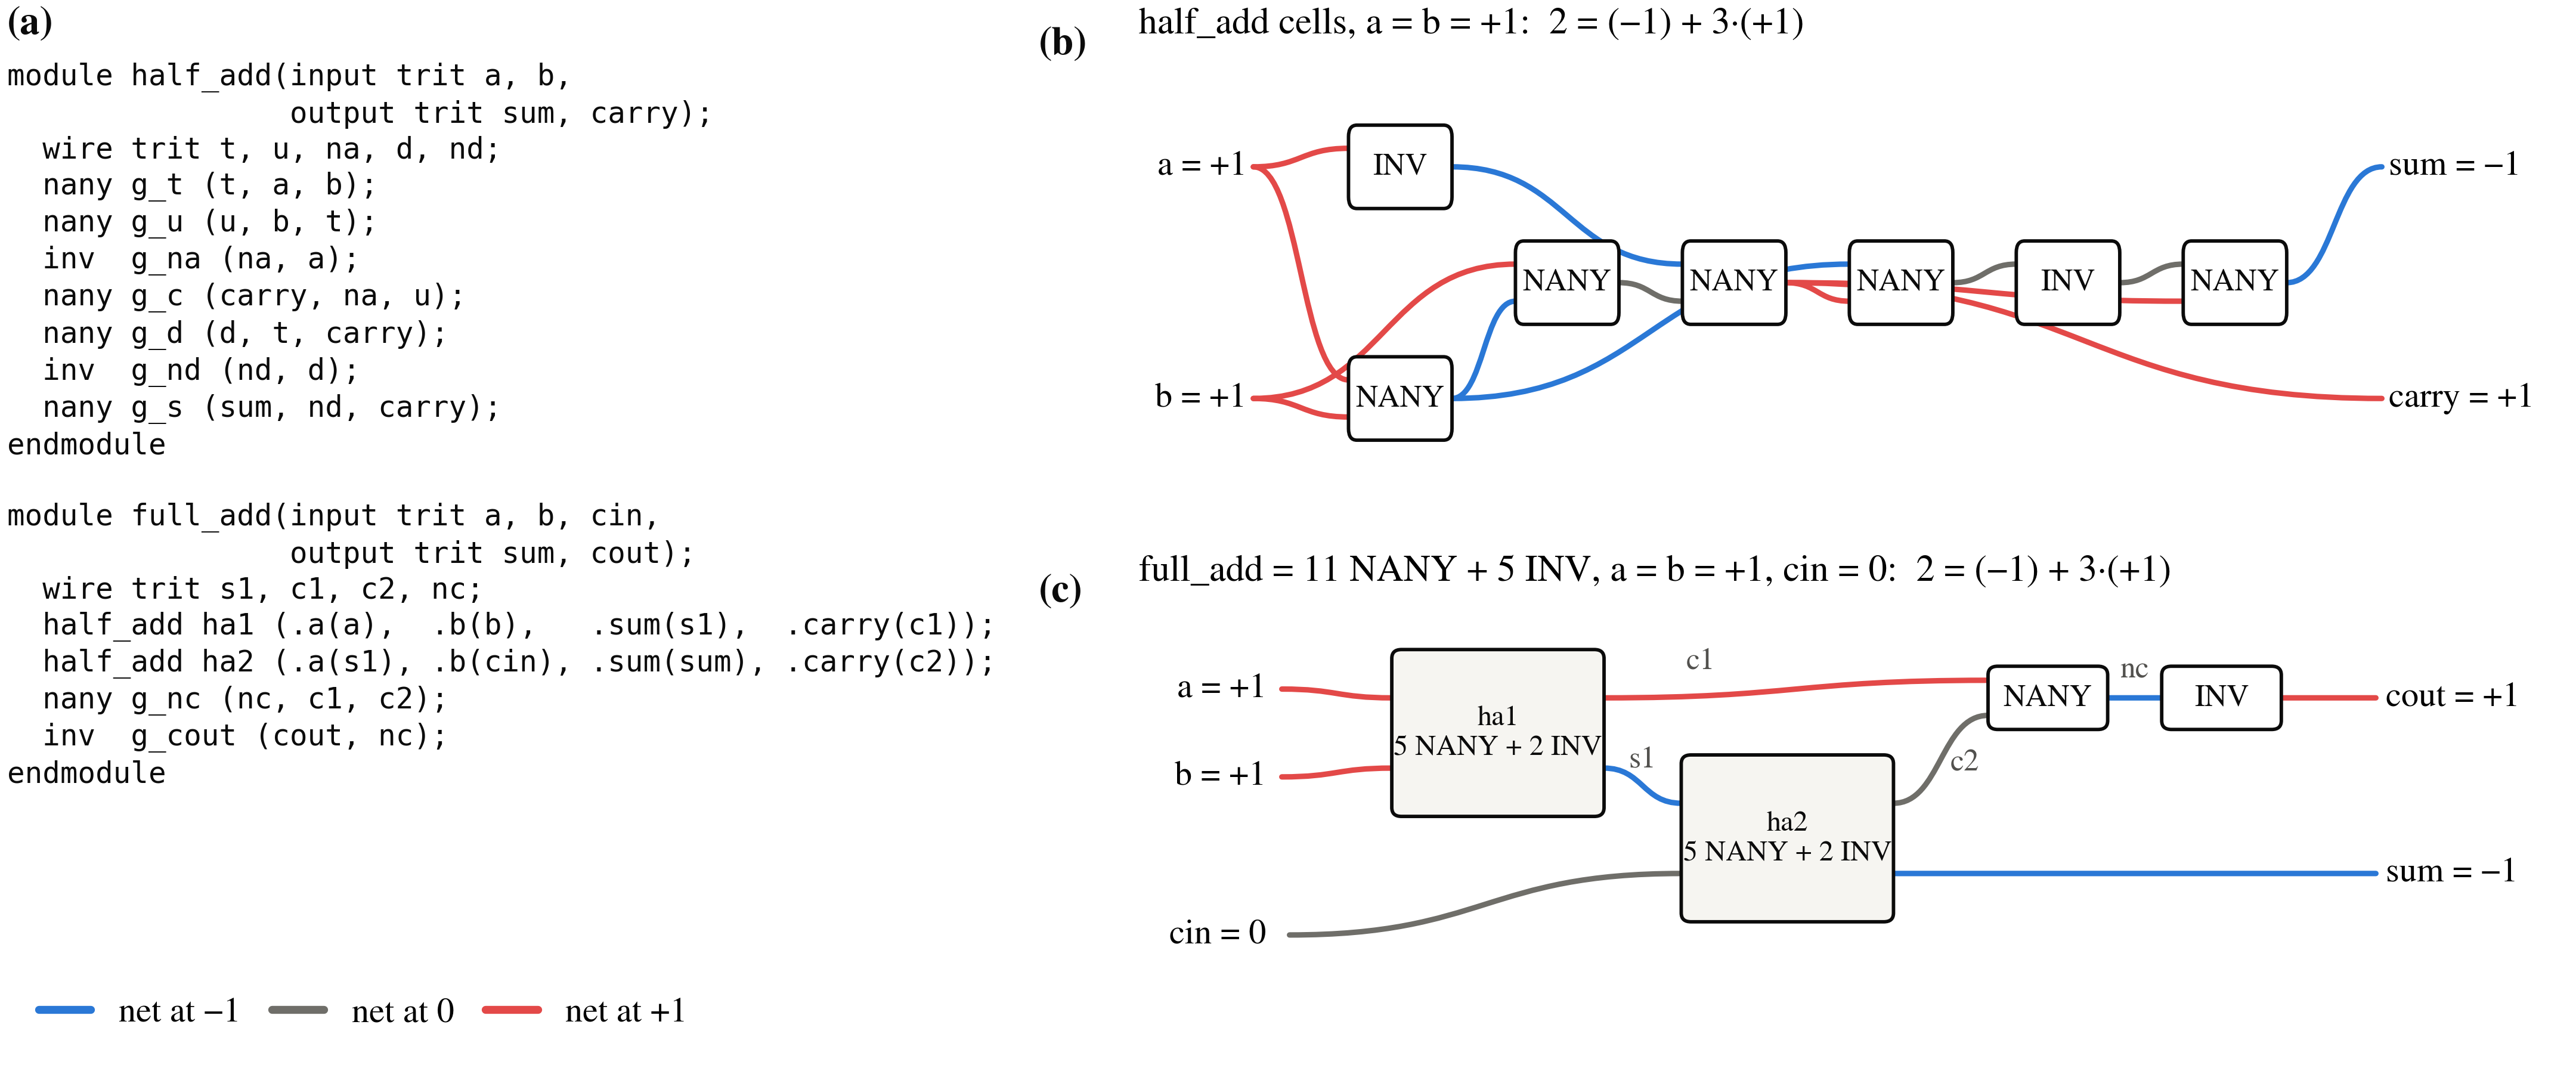

**Arithmetic expressed as ternary cells** (a) Shared half-adder and full-adder
HDL, (b) the mapped half adder with 5 NANY and
2 INV cells, and (c) the full-adder hierarchy with
11 NANY and 5 INV cells.
Net colors show settled negative, middle and positive trits for the illustrated
inputs; the sum and carry preserve the integer total in both examples.

> **What this shows.** The half adder contains 5 NANY and
> 2 INV cells; the full adder contains
> 11 NANY and 5 INV cells.
> The full-adder hierarchy reuses the half adder and combines its carries
> through NANY followed by INV.


In [8]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('arithmetic', '4. Describe signed arithmetic in TritVerilog', requires=[]):
    ha = flow.load(ROOT/"examples/half_add.tv", "half_add")
    fa = flow.load(ROOT/"examples/full_add.tv", "full_add")
    details_html("Half-adder exhaustive truth table",truth_table_html(ha.design))
    details_html("Full-adder exhaustive truth table",truth_table_html(fa.design))
    fa_table = fa.truth_table()
    ha_table = ha.truth_table()
    assert np.array_equal(ha_table["a"]+ha_table["b"], ha_table["sum"]+3*ha_table["carry"])
    assert np.array_equal(fa_table["a"]+fa_table["b"]+fa_table["cin"],
                          fa_table["sum"]+3*fa_table["cout"])
    ha_counts, fa_counts = ha.synthesize().report()["cells"], fa.synthesize().report()["cells"]
    schematic_sources = json.loads((ROOT/"notebook/assets/schematics/manifest.json").read_text())["schematics"]
    ha_symbols = schematic_sources["half_adder"]["instances_by_symbol"]
    fa_symbols = schematic_sources["full_adder"]["instances_by_symbol"]
    symbol_names = {"INV":"inverter", "NANY":"nany"}
    assert ha_counts == {cell:ha_symbols[symbol] for cell,symbol in symbol_names.items()}
    assert fa_counts == {cell:fa_symbols["half_adder"]*ha_counts[cell]+fa_symbols[symbol]
                         for cell,symbol in symbol_names.items()}
    table([["Circuit", "Cells", "Exhaustive input states"],
           ["half_add",ha_counts,len(ha_table["sum"])], ["full_add",fa_counts,len(fa_table["sum"])]])
    evidence("Ripple-adder HDL", (ROOT/"examples/adder.tv").read_text())


Vector,ainput,binput,sumoutput,carryoutput
1,-1,-1,+1,-1
2,-1,0,-1,0
3,-1,+1,0,0
4,0,-1,-1,0
5,0,0,0,0
6,0,+1,+1,0
7,+1,-1,0,0
8,+1,0,+1,0
9,+1,+1,-1,+1


Vector,ainput,binput,cininput,sumoutput,coutoutput
1,-1,-1,-1,0,-1
2,-1,-1,0,+1,-1
3,-1,-1,+1,-1,0
4,-1,0,-1,+1,-1
5,-1,0,0,-1,0
6,-1,0,+1,0,0
7,-1,+1,-1,-1,0
8,-1,+1,0,0,0
9,-1,+1,+1,+1,0
10,0,-1,-1,+1,-1


Circuit,Cells,Exhaustive input states
half_add,INV: 2; NANY: 5,9
full_add,INV: 5; NANY: 11,27


## 5. Follow an expression into cells

Synthesis expands parameters and hierarchy, simplifies ternary expressions,
then maps them to the library. Follow one signal from the source hierarchy
through the half-adder graph in the preceding figure. Its net colors expose
intermediate trits as well as the final sum and carry.

In the [mapped half adder](#4.-Describe-signed-arithmetic-in-TritVerilog), blue, gray and
red traces carry −1, 0 and +1. Follow the shared intermediate nets before
checking the sum and carry.

A negated minimum maps directly to NAND; a positive minimum adds INV.
The analogous rule uses NOR for maximum. Constants map to TIE cells.
Synthesis removes double inversion, shares common expressions and removes
unused logic using identities that hold for trits. Explicit live gate instances
retain their cell type. Buffer trees limit fanout, and the equivalence check
compares the original source with the final cell network.

> **What this shows.** The mapped half adder has 7 cells:
> 5 NANY and 2 INV.
> At the illustrated positive inputs it produces a negative sum digit and
> a positive carry, preserving the integer total.

The same cell network now supplies both the physical placer and the schematic
reference for layout verification.


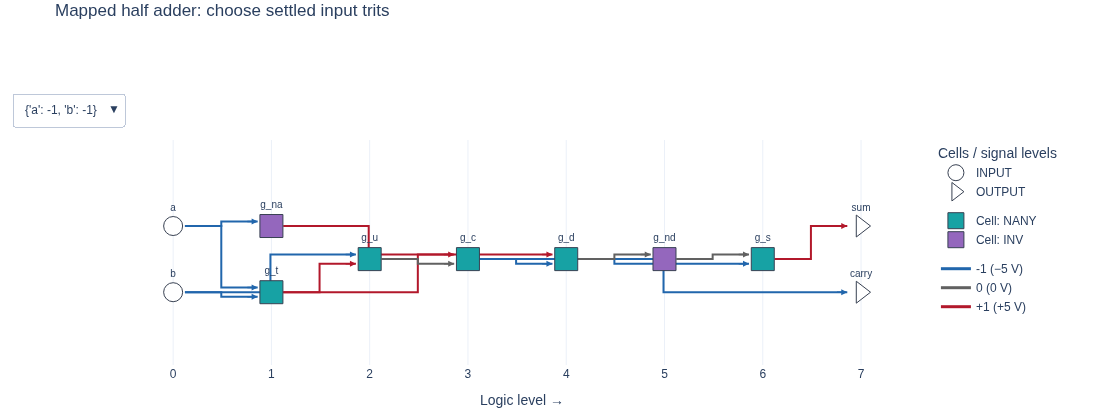

Report field,Value
top,full_add
cells,INV: 5; NANY: 11
total_cells,16
logic_depth,12
hierarchy,<top>: INV: 1; NANY: 1; ha1: INV: 2; NANY: 5; ha2: INV: 2; NANY: 5
max_fanout,3
fanout_limit,4
equivalence,passed: True; mode: exhaustive; vectors: 27; seed: None


HDL expression,Computed cells
~a,INV: 1
~(a&b),NAND: 1
a&b,INV: 1; NAND: 1
~(a|b),NOR: 1
a|b,INV: 1; NOR: 1
"nany(a,b)",NANY: 1
1'tT,TIEN: 1
1't0,TIEZ: 1
1't1,TIEP: 1


In [9]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('synthesis', '5. Follow an expression into cells', requires=[]):
    fa = flow.load(ROOT/"examples/full_add.tv", "full_add")
    fa_table = fa.truth_table()
    fa_net = fa.synthesize()
    assert fa_net.report()["equivalence"]["passed"]
    assert fa_net.report()["equivalence"]["vectors"] == len(fa_table["sum"])
    half_net = flow.load(ROOT/"examples/half_add.tv","half_add").synthesize()
    show(value_selector(half_net))
    table([["Report field", "Value"]]+[[k,v] for k,v in fa_net.report().items()],details="Full synthesis report")
    from tritflow.synth import tritverilog
    evidence("Gate-level TritVerilog", tritverilog(fa_net))
    mapping_cases = [("~a",["INV"]), ("~(a&b)",["NAND"]), ("a&b",["NAND","INV"]),
                     ("~(a|b)",["NOR"]), ("a|b",["NOR","INV"]), ("nany(a,b)",["NANY"]),
                     ("1'tT",["TIEN"]), ("1't0",["TIEZ"]), ("1't1",["TIEP"])]
    mapping_rows = [["HDL expression", "Computed cells"]]
    for expr, expected_cells in mapping_cases:
        mapped = flow.loads(f"module mapping(input trit a,b,output trit y); assign y={expr}; endmodule").synthesize()
        assert sorted(inst.cell for inst in mapped.instances) == sorted(expected_cells)
        mapping_rows.append([expr, mapped.report()["cells"]])
    table(mapping_rows,details="Expression-to-cell mapping checks")



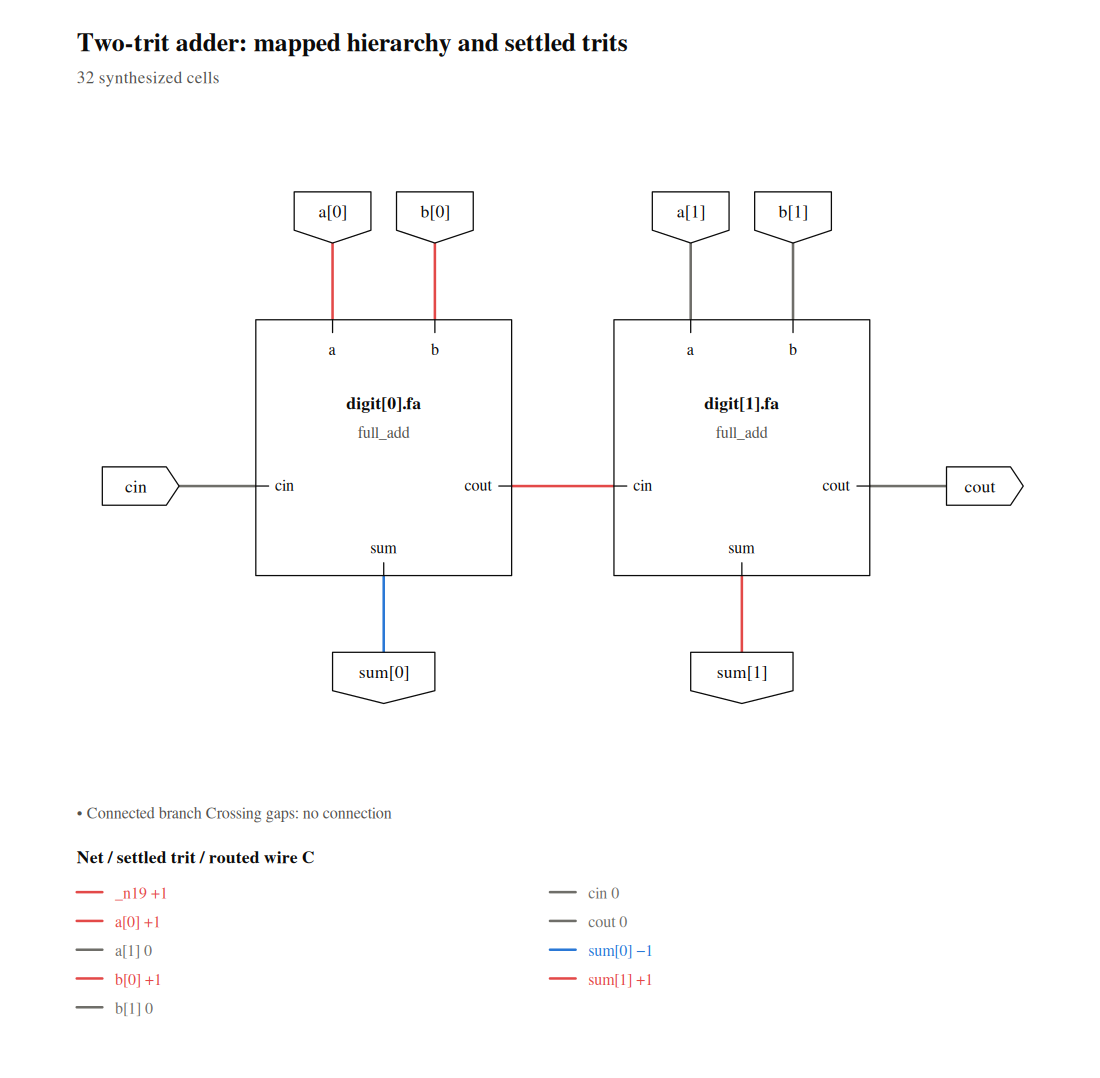


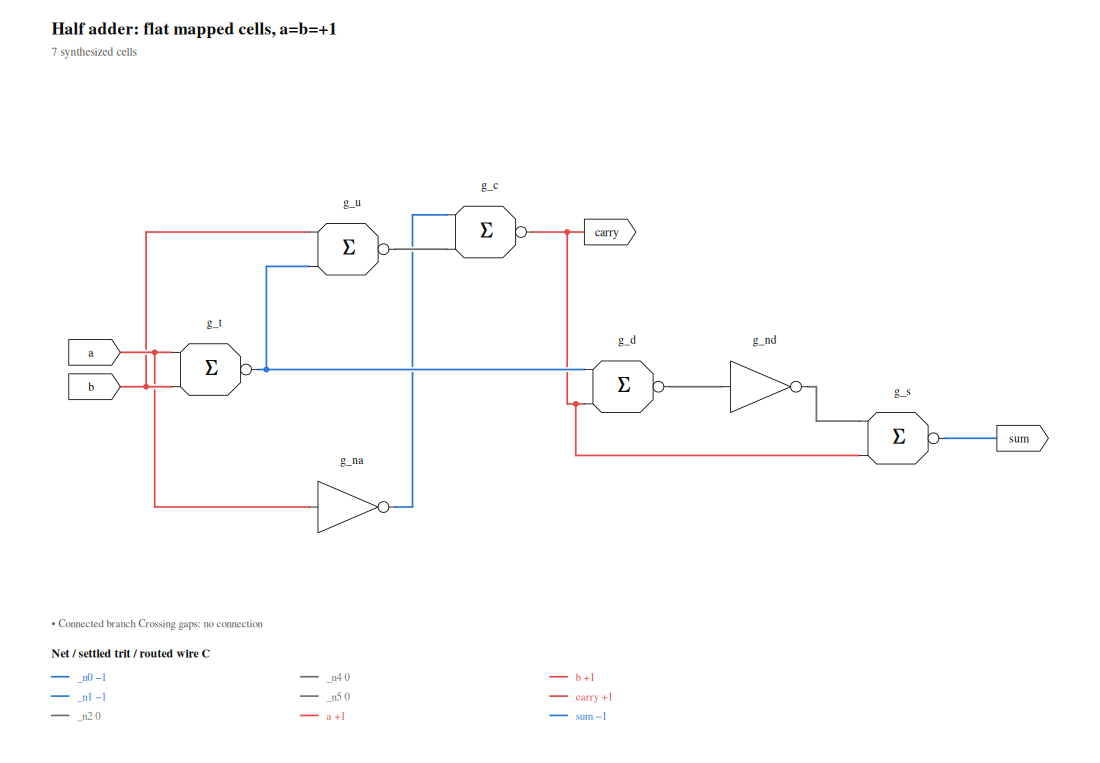

In [10]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('schematic', '5. Follow an expression into cells', requires=[]):
    schematic_net = flow.load(ROOT/"examples/adder.tv", "adder", {"N":2}).synthesize(name="adder2_demo")
    schematic_inputs = {"a[0]":1,"a[1]":0,"b[0]":1,"b[1]":0,"cin":0}
    sch = schematic_net.schematic(inputs=schematic_inputs,net_names=True,
                                 title="Two-trit adder: mapped hierarchy and settled trits")
    half_net = flow.load(ROOT/"examples/half_add.tv", "half_add").synthesize()
    half_sch = half_net.schematic(expand="*",inputs={"a":1,"b":1},net_names=True,
                                  title="Half adder: flat mapped cells, a=b=+1")
    details_svg("Mapped adder hierarchy (settled trits)", sch.svg)
    details_svg("Flat mapped half adder (settled trits)", half_sch.svg)


## 6. Route signals and feed the standing current

Placement arranges cells in rows with routing channels between them. A seeded
annealing search reduces estimated connection length; a grid router connects
the pins on two metals. M1 signal routes stay in channels, while M2 can cross
cells through unobstructed tracks. The three supplies need enough metal and
feed points to carry the cells' static current.

The router checks connectivity, spacing and via enclosure, then runs the PDK
drawing-DRC deck. LVS compares the extracted devices and connections with
the mapped schematic. The figure colors cells by arithmetic digit and shows
the recorded half-perimeter wirelength during placement.



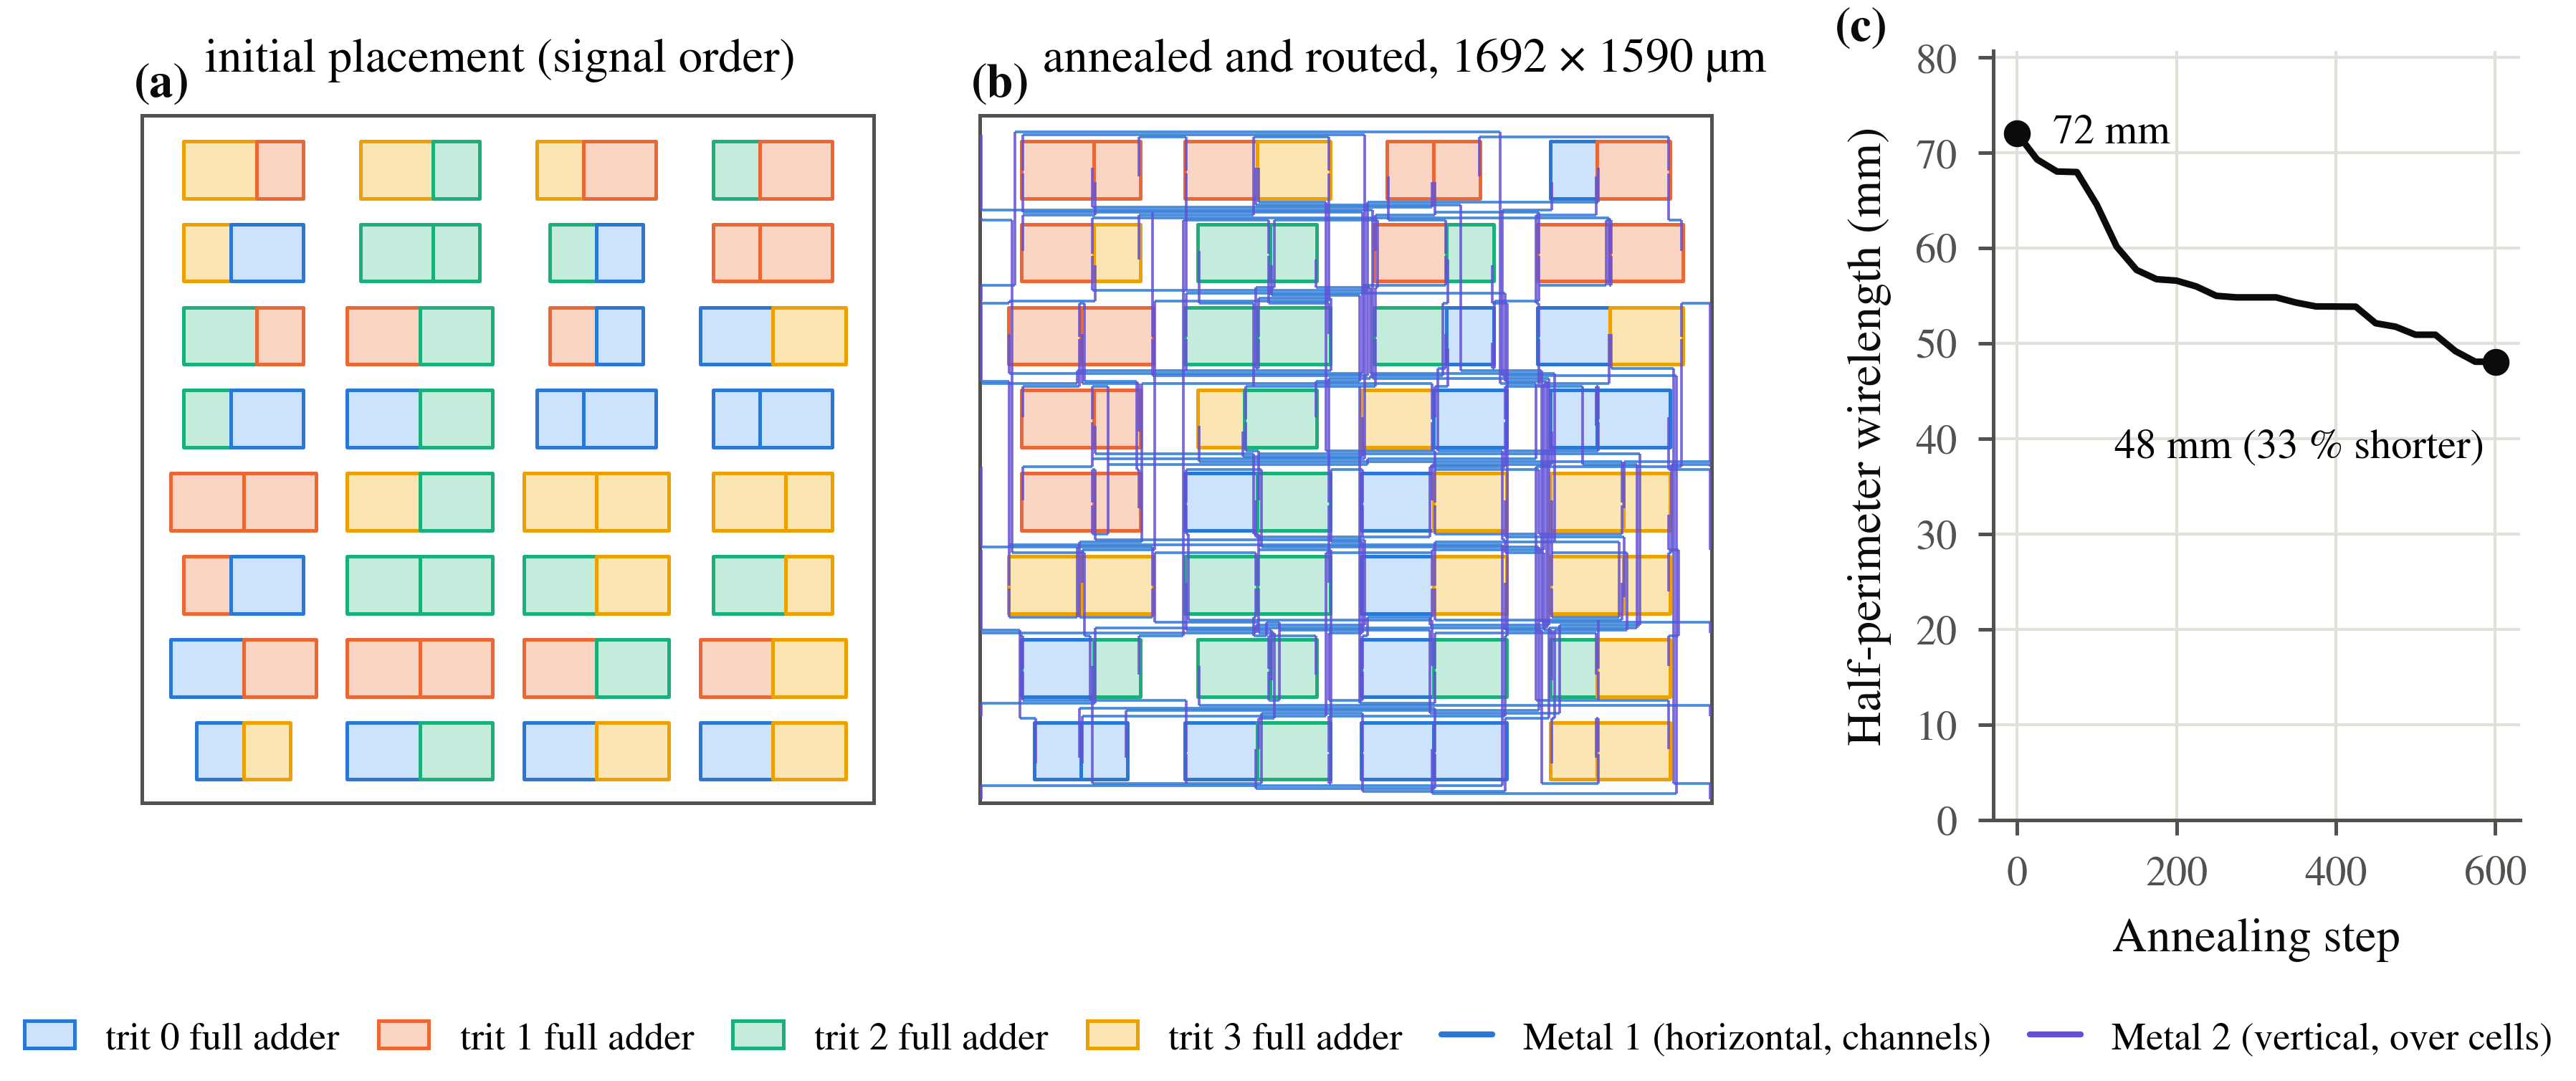

**Placement and routing of the illustrated adder** (a) Initial placement in
signal order, (b) the annealed and routed 4-trit layout
occupying 1692 × 1590 µm in run paper/adder4 · seed 7, and (c) the
recorded cell-terminal HPWL.
Annealing reduces HPWL from 72.04 to
48.07 mm, a 33.27% reduction;
cell colors identify full-adder digits, while the routes distinguish
horizontal M1 in channels from vertical M2 over the cells.

> **What this shows.** The illustrated 4-trit adder occupies
> 1692 × 1590 µm. Cell-terminal HPWL falls from
> 72.04 to 48.07 mm during
> annealing, a 33.27% reduction.

The layout is now the source of both device extraction and wire geometry for
the electrical comparison.


In [11]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('pnr', '6. Route signals and feed the standing current', requires=['opening']):
    table([["Metric", "Two-trit adder"]]+[[k,v] for k,v in lay.stats.items()],details="Full physical statistics")
    assert all(check["clean"] for check in lay.data["checks"].values())
    assert lay.stats["routed_nets"] == len(net.nets())
    assert {p["orient"] for p in lay.data["placements"]} <= {"R0","MY"}
    evidence("Live adder physical checks",lay.data["checks"])
    table([["Initial / final cell-terminal HPWL (µm)",
            [lay.data["history"][i]["hpwl"] for i in (0,-1)]]])
    if EXTENDED:
        show(placement_animation(lay.data))
    if EXTENDED:
        show(routing_progress(lay.data))
    RUN_FLOORPLAN_EXPERIMENT = False  # opt in after changing the controls below
    EXPERIMENT_ROWS, EXPERIMENT_ANNEAL_STEPS, EXPERIMENT_SEED = None, 2400, 7
    if RUN_FLOORPLAN_EXPERIMENT:
        folder = BUILD/"floorplan_experiment"
        def route_experiment():
            routed = net.place_and_route(output_dir=folder, rows=EXPERIMENT_ROWS,
                       anneal_steps=EXPERIMENT_ANNEAL_STEPS, seed=EXPERIMENT_SEED)
            drc, lvs = routed.drc(), routed.lvs()
            assert drc["clean"] and lvs["matched"]
            return {"stats":routed.stats, "drc":drc, "lvs":lvs}
        trial = cache.run("floorplan-experiment", {"net":net.to_json(),"rows":EXPERIMENT_ROWS,
                         "steps":EXPERIMENT_ANNEAL_STEPS,"seed":EXPERIMENT_SEED}, route_experiment,
                         artifacts=[folder/f"{net.top}.gds",folder/f"{net.top}.pnr.json"])
        assert trial["drc"]["clean"] and trial["lvs"]["matched"]
        table([["Measured floorplan experiment",trial["stats"]]])
        show(placement_animation(flow.load_layout(net,folder).data))


Metric,Two-trit adder
die_size_um,"[1284, 1038]"
die_area_um2,1.333e+06
wirelength_um,M1: 1.443e+04; M2: 1.499e+04
via_count,246
power_via_count,480
utilization,0.473
instance_count,32
row_count,6
net_count,37
spans_per_row,3


Initial / final cell-terminal HPWL (µm),"[2.756e+04, 1.421e+04]"


## 7. Does the layout still work?

Timing must say when an output becomes a valid trit. Here it is the time from
input-ramp start until the output enters the target's ±0.5 V band
and stays there through the input interval. Compare the same extracted devices
with and without estimated wire capacitance, then increase output load and
adder width. The carry path and static power give two predictions to test.

**Predict first.** Use a single full-adder slice to estimate a ripple path.
Let $t_{c,1}$ be its carry settling and $t_{e,1}$ its slower carry-or-sum
endpoint. Each added digit contributes another carry stage.

$$
t_{\mathrm{hand}}(N)=t_{e,1}+(N-1)t_{c,1}.
$$

For the all-zero input, count the mapped cells and sum their zero-input DC
powers. The rail currents retain SPICE's signed voltage-source convention.

$$
P_c(0)=-\sum_{r\in\{DD,MID,SS\}} V_r I_{r,c}(0),\qquad
P_{\mathrm{hand}}(N)=\sum_c n_c(N)P_c(0).
$$



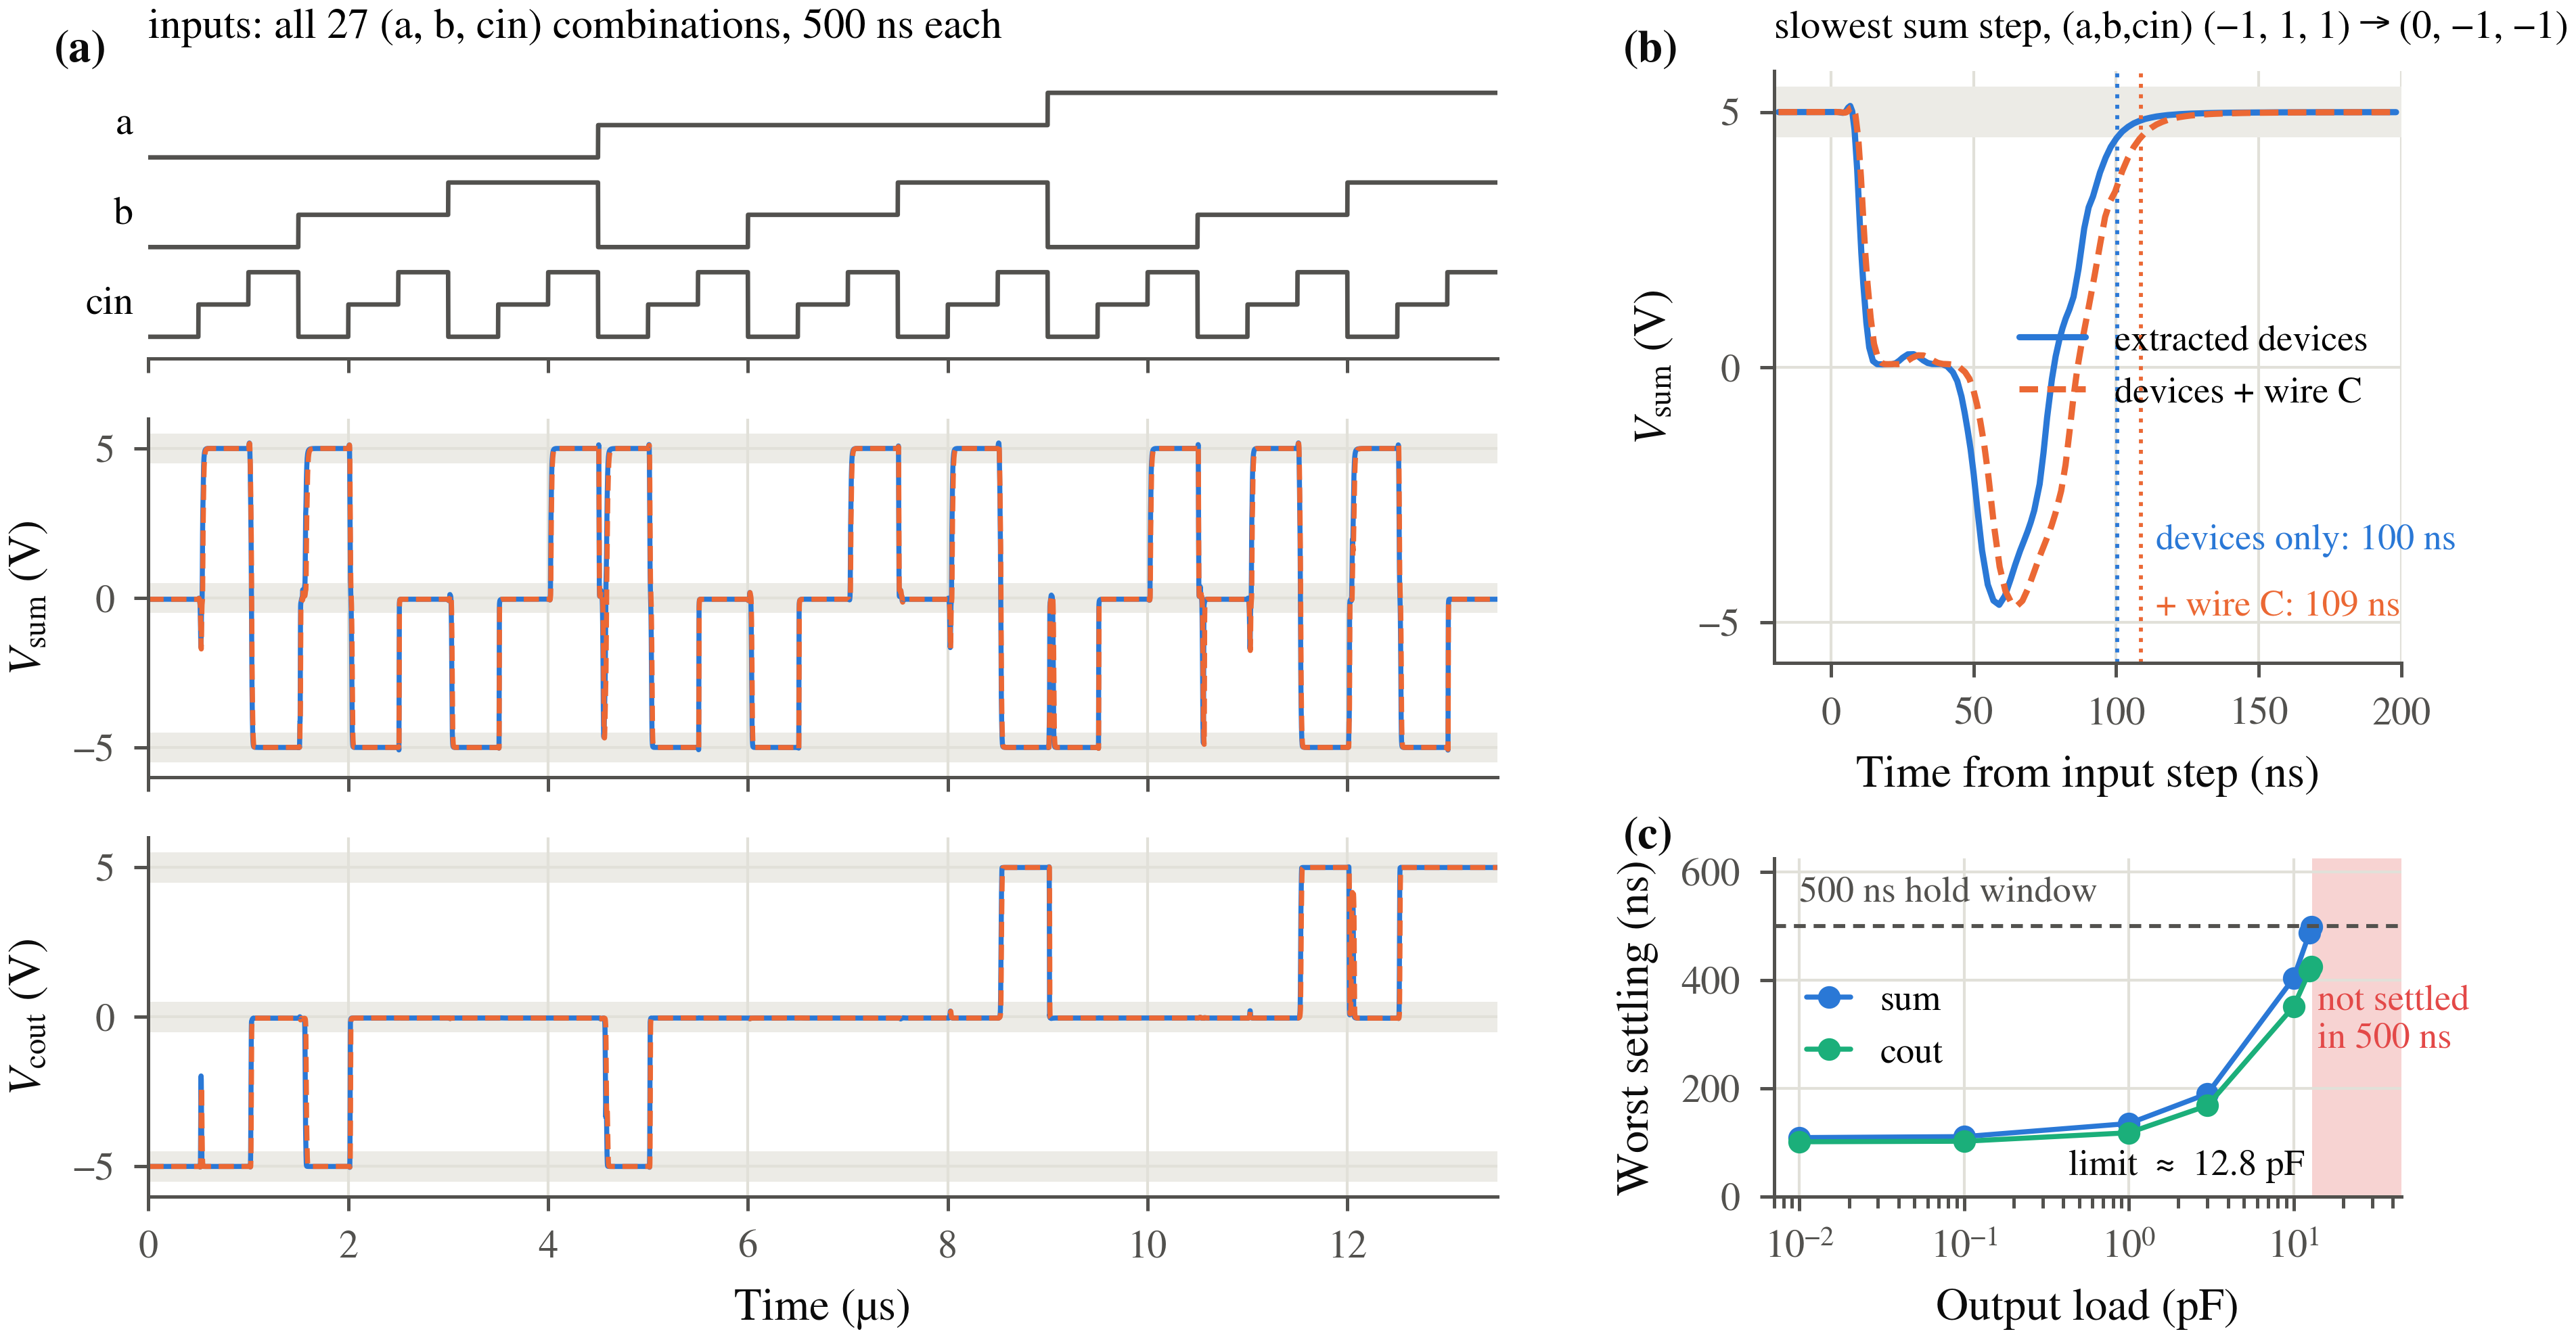

**Full-adder settling and the observed load boundary** (a) The full adder
in run paper/full_add · seed 19 visits 27 input states with
500 ns intervals
and 10 fF per output; device-only and device-plus-wire-C
outputs meet the ±0.5 V criterion.
(b) On the transition with the largest post-wire sum settling, final band
entry changes from 100.3 to 108.6 ns
when estimated wire capacitance is added to the same extracted devices.
(c) The equal-output-load sweep brackets an observed pass and failure between
12.81 and 12.97 pF within its
500 ns intervals.


Running: adder2-pre



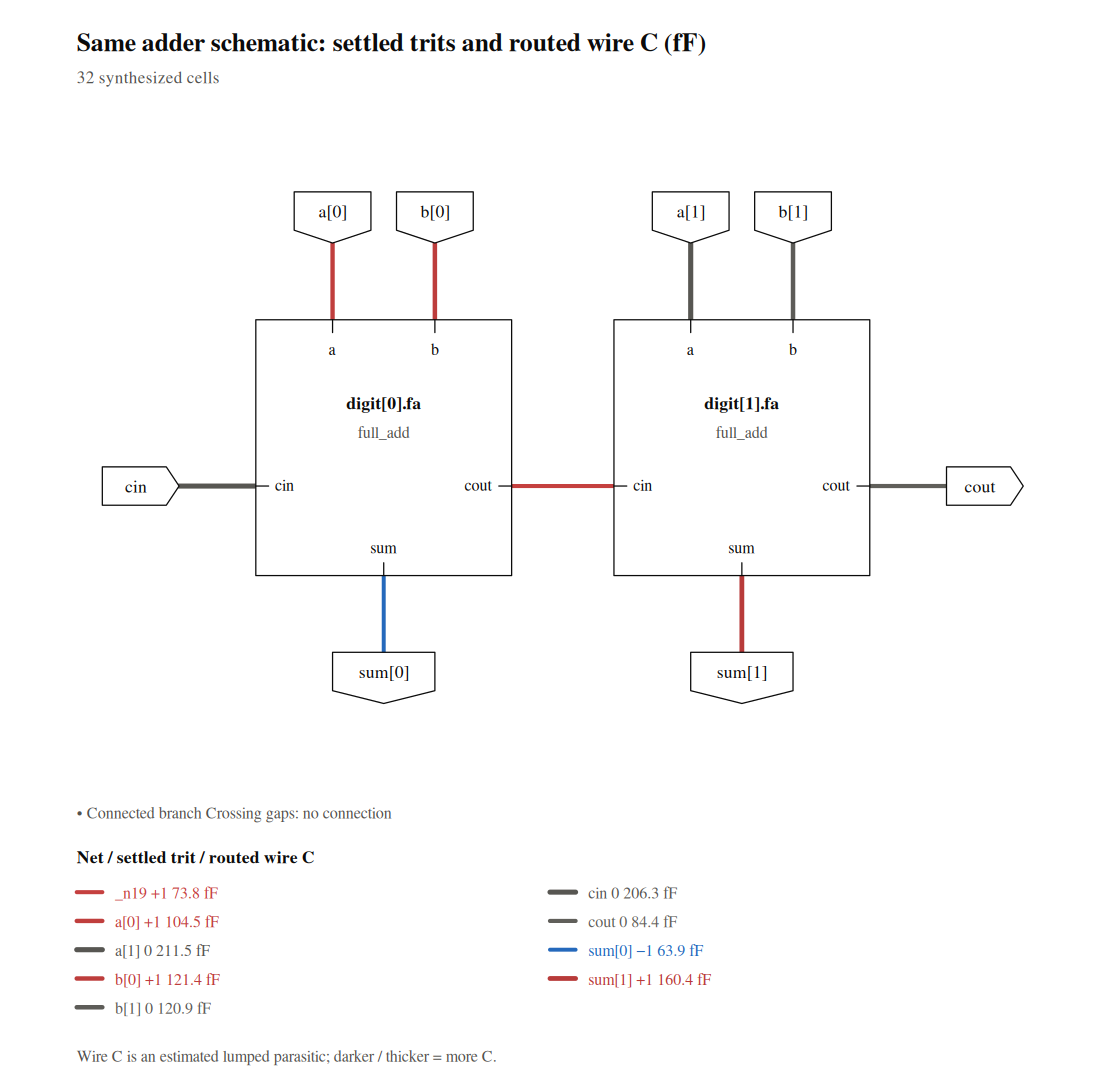

In [12]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('pre', 'Chapter 7: Does the layout still work?', requires=['opening', 'schematic']):
    pre = cache.run("adder2-pre", {"net":net.to_json(),"vectors":vectors,"load":LOAD_F,
                                 "gds_sha256":hashlib.sha256(lay.gds_path.read_bytes()).hexdigest(),
                                 "hold":HOLD_S,"step":STEP_S,"edge":EDGE_S,"temperature_c":TEMP_C}, lambda:
        lay.extract(wire_c=False).simulate(vectors, load=LOAD_F, expected=adder_reference, hold_s=HOLD_S,
                     step_s=STEP_S, edge_s=EDGE_S, temperature_c=TEMP_C,
                     nodeset=demo["initial_nodeset_v"], timeout=600))
    assert pre["measurements"]["passed"]
    assert pre["stimulus"]["vectors"] == demo["stimulus"]["vectors"]
    assert pre["stimulus"]["hold_s"] == demo["stimulus"]["hold_s"]
    assert pre["stimulus"]["step_s"] == demo["stimulus"]["step_s"]
    assert schematic_net.to_json() == net.to_json(), "schematic and routed references must be identical"
    wire_report = lay.result.net_parasitics()
    routed_sch = sch.annotate(parasitics=wire_report,
                             title="Same adder schematic: settled trits and routed wire C (fF)")
    assert routed_sch.scene is sch.scene
    details_svg("Same adder scene with measured routed wire-C overlay",routed_sch.svg)
    evidence("Schematic wire-C scope (excludes receiving-pin C)",wire_report["assumptions"])
    if EXTENDED:
        for load in [10e-15,1e-12]:
            loaded = cache.run(f"adder2-load-{load:g}", {"vectors":vectors,"load":load}, lambda:
                lay.extract().simulate(vectors, load=load, expected=adder_reference,
                                       hold_s=2e-6, step_s=2e-9, timeout=180))
            assert loaded["measurements"]["passed"], loaded["measurements"]
            print(load, loaded["measurements"]["passed"], loaded["measurements"]["max_settling_s"])


The middle level has a standing cost: 4.17 mW per mapped cell for this adder mix, reaching 0.4 W at 6 trits. Sizing trades current against voltage accuracy.

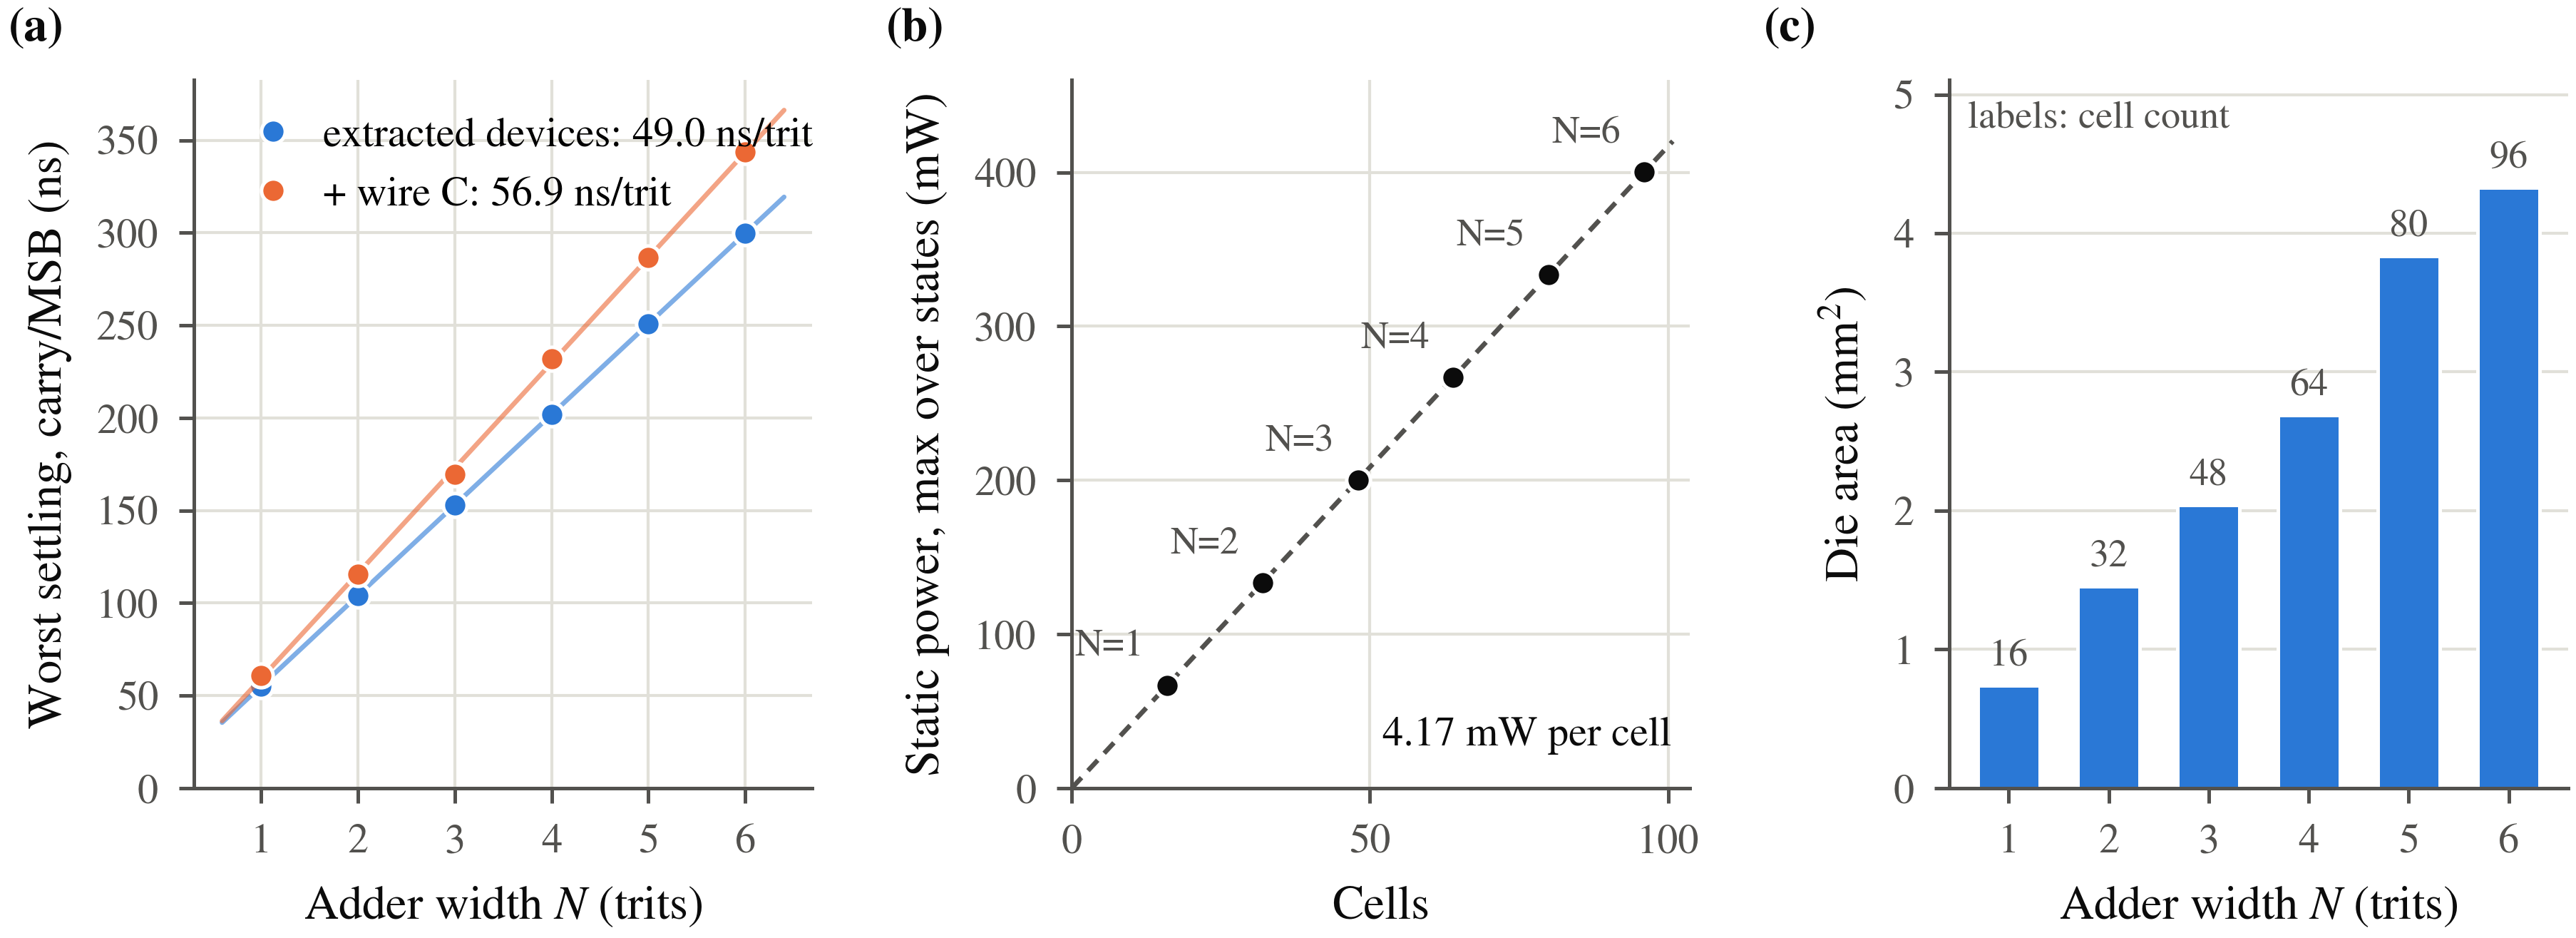

**Ripple-adders generated from one parameterized HDL source** Adders of
width 1–6 trits are synthesized,
routed, drawing-DRC/LVS checked and simulated at 10 fF
per output under nominal models (run family width-sweep · seed 7).
(a) Fits to the recorded carry-endpoint settling give
48.95 ns/trit for extracted devices alone and
56.88 ns/trit with estimated wire capacitance.
(b) The tested-state DC-power maxima give an effective
4.169 mW per mapped cell for this adder mix;
(c) die area and cell count show the physical cost of increasing width.

> **What this shows.** With 27 full-adder states and
> 500 ns input intervals, the load test brackets a pass and failure
> between 12.81 and 12.97 pF per output.
> Over widths 1–6, fitted
> carry-endpoint settling slopes are 48.95 ns/trit for
> devices alone and 56.88 ns/trit with wire capacitance.
> The tested-state static-power fit gives 4.169 mW per
> mapped cell, reaching 400.2 mW at width 6.

Compare the hand estimates with the widest displayed adder. The delay
comparison uses the same carry and most-significant-sum endpoints as the plot;
the power comparison uses a separate all-zero DC state.

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Quantity</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Hand estimate</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">SPICE</th></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Carry-path settling, devices only (ns)</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">278.9</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">299.7</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">All-zero static power (mW)</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">400.2</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">400.2</td></tr>
</table>
</div>

The current flows with the inputs held still; reducing switching frequency
alone does not remove it. The separate rail-network results appear in Appendix B.

These results cover the displayed input sequences and model conditions;
Appendix A collects their scope.


In [13]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('published', 'Chapter 7: Does the layout still work?', requires=[]):
    from tritflow.sim.scaling import load_scaling
    from tritflow.sim.load_sweep import load_sweep_results
    from tritflow.viz.scaling import scaling_figure, load_sweep_figure, scaling_fit_figure
    for filename, loader, figure in [("adder_scaling.json",load_scaling,scaling_figure),
                                      ("full_add_load_sweep.json",load_sweep_results,load_sweep_figure)]:
        published = ROOT/"results"/filename
        result = loader(published)
        records = result["rows"] if filename == "adder_scaling.json" else [result]
        compatible_sources = []
        for record in records:
            compatible_sources.extend(verify_publication_sources(record,ROOT,PDK_ROOT))
        if compatible_sources:
            evidence("Recorded-source compatibility: exact optional schematic delegate only",compatible_sources)
        evidence("Published experiment scope: "+filename,result.get("coverage",result.get("scope")))
        evidence("Published limits / conditions",result.get("limits",result.get("conditions")))
        if filename == "adder_scaling.json":
            table([["Width", "Routing realization", "Recorded state", "PASS", "Error"]]+
                  [[r["n"],f"width-sweep/adder{r['n']} · seed {r['seed']}",r["state"],r["passed"],r["error"]] for r in result["rows"]])
        else:
            table([["Measured boundary (F)",result["boundary"]], ["Boundary found",result["boundary_found"]],
                   ["Outputs / input-state count",[result["outputs"],len(result["vectors"])]]])
        if EXTENDED:
            show(figure(result))
        if filename == "adder_scaling.json":
            if EXTENDED:
                show(scaling_fit_figure(result))


Width,Routing realization,Recorded state,PASS,Error
1,width-sweep/adder1 · seed 7,complete,True,None
2,width-sweep/adder2 · seed 7,complete,True,None
3,width-sweep/adder3 · seed 7,complete,True,None
4,width-sweep/adder4 · seed 7,complete,True,None
5,width-sweep/adder5 · seed 7,complete,True,None
6,width-sweep/adder6 · seed 7,complete,True,None


Measured boundary (F),last_pass_f: 1.281e-11; first_fail_f: 1.297e-11; coarse_first_fail_f: 3e-11; width_f: 1.563e-13
Boundary found,True
Outputs / input-state count,"[[sum, cout], 27]"


## 8. Change the circuit and close the loop

Choose a sign detector, signed comparator, multiplier or min/max sorter.
Read its mathematical specification, then edit the HDL below and run the
design cell. The truth table first compares both source and mapped logic
with an independent integer reference. Placement, routing, drawing DRC, LVS
and extracted simulation then follow the same path as the opening adder.

*Set the circuit choice in the code cell, inspect its HDL, then change an
expression. The generated layout and waveform belong to that edited source.*

Keep the arithmetic reference while making an equivalent implementation.
If you change the intended function, edit that specification as well.
For a deliberate first experiment, try replacing a minimum with a maximum
in the sorter: the truth-table check identifies the disagreement before routing.



**Successful first edit:** the visible sorter below implements its minimum as `~((~a) | (~b))`. Run it to obtain a new mapped schematic and GDS while keeping the independent sorting reference.


In [14]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('edit', 'Chapter 8: Change the circuit and close the loop', requires=[]):
    from examples.curated import DESIGNS
    from tritflow.synth import evaluate_netlist
    CHOICE = os.environ.get("TRITFLOW_CIRCUIT", "minmax")  # sign | compare2 | mul2 | minmax
    example = DESIGNS[CHOICE]
    # Edit this HDL literal, then run the next cell. This successful first edit
    # replaces min(a,b) with its equivalent De Morgan expression on trits.
    source = """module minmax(input trit a, b, output trit lo, hi);
      assign lo = ~((~a) | (~b));
      assign hi = a | b;
    endmodule
    """ if CHOICE == "minmax" else example.path.read_text()
    print(example.description)
    display(Code(source,language="verilog"))


Sort two scalar trits into ascending order


module minmax(input trit a, b, output trit lo, hi);
      assign lo = ~((~a) | (~b));
      assign hi = a | b;
    endmodule

Vector,ainput,binput,looutput,hioutput
1,-1,-1,-1,-1
2,-1,0,-1,0
3,-1,+1,-1,+1
4,0,-1,-1,0
5,0,0,0,0
6,0,+1,0,+1
7,+1,-1,-1,+1
8,+1,0,0,+1
9,+1,+1,+1,+1


Running: your-minmax


Independent arithmetic input states,9
Physical results,"die_size_um: [384, 366]; die_area_um2: 1.405e+05; wirelength_um: M1: 1482; M2: 1385; via_count: 32; power_via_count: 80; utilization: 0.4734; instance_count: 4; row_count: 2; net_count: 6; spans_per_row: 1; channel_tracks: 4; aspect_ratio: 1.049; anneal_steps: 600; routed_nets: 6; library_mock: False; max_supply_drop_v: 0.001178; bypass_tracks_per_side: 0; hpwl_before_um: 932; hpwl_after_um: 416; hpwl_improvement_pct: 55.36; runtime_s: placement: 0.006418; routing: 0.007683; export_and_verification: 1.009; total: 1.023"
DRC clean / LVS matched,"[True, True]"
Initial Newton guesses (V),pre: xdut.n_ex_I7: 5; xdut.n_ex_I6: 5; post: xdut.n_ex_I7: 5; xdut.n_ex_I6: 5


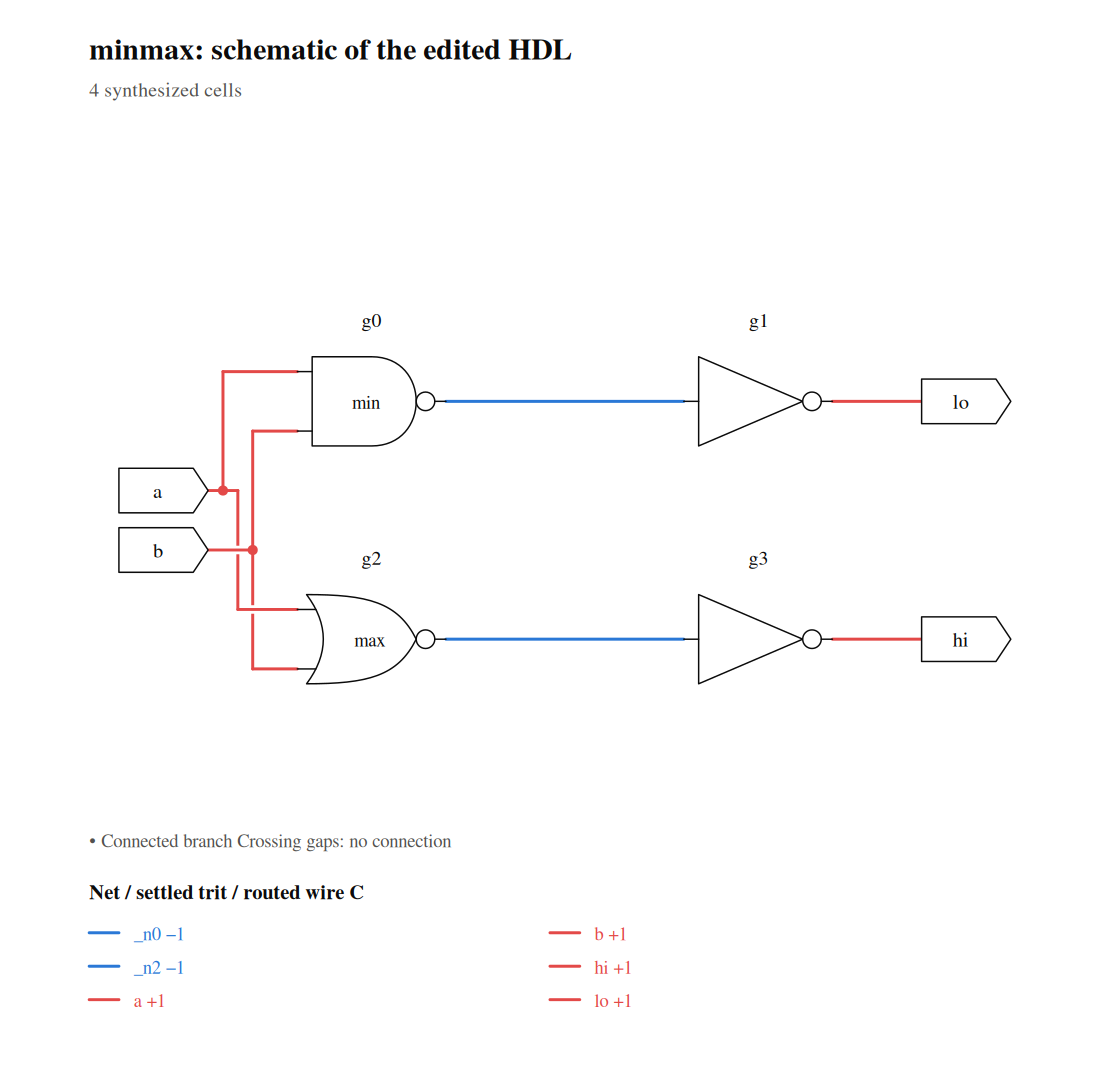

Running: your-minmax-raster


**Edited `minmax`: actual GDS, DRC-clean and strict-LVS matched.** Axes are in µm.

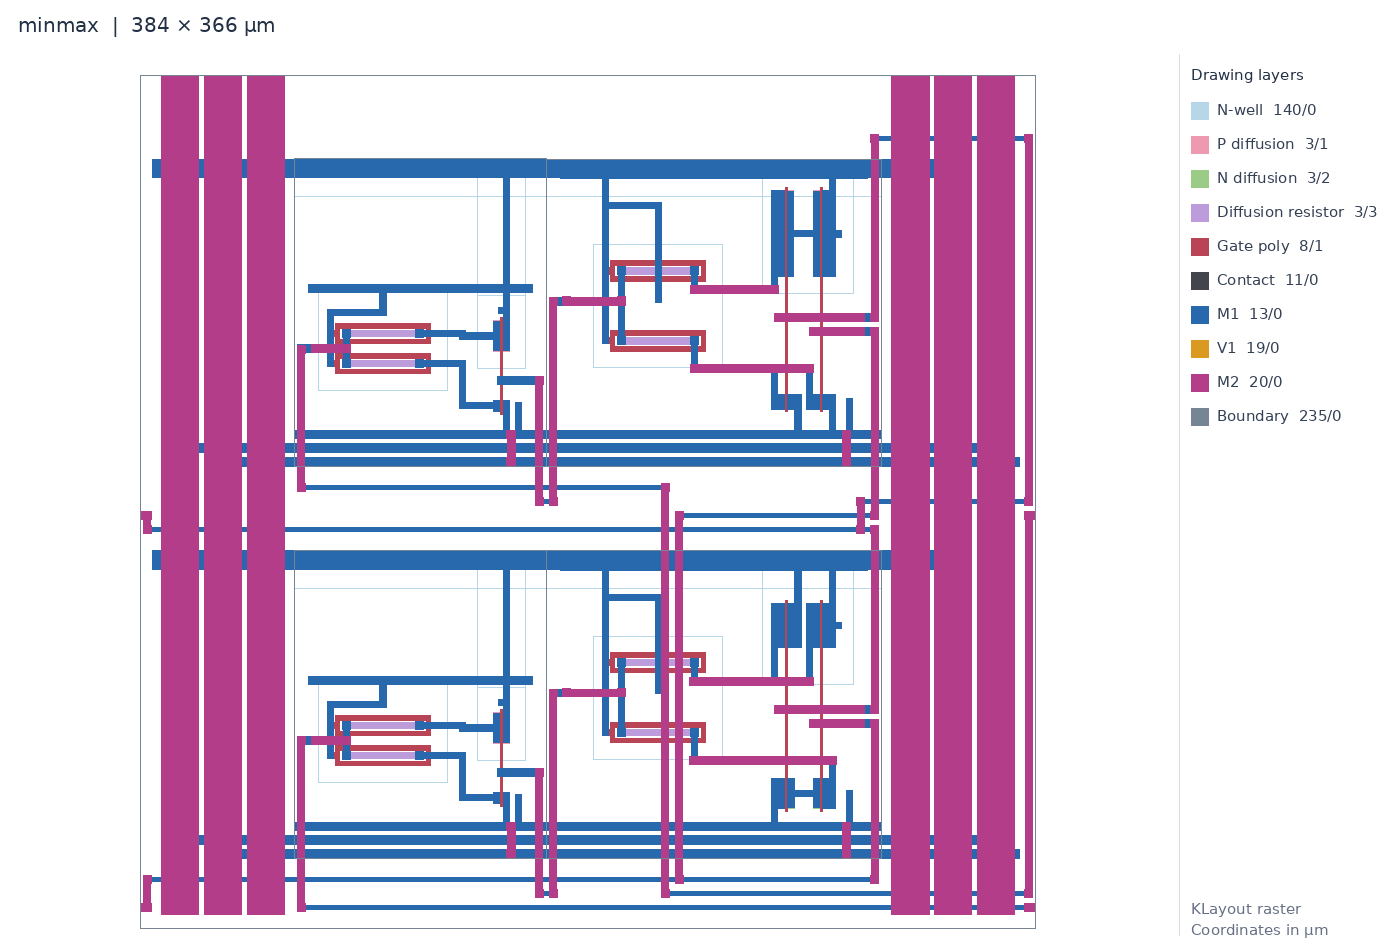

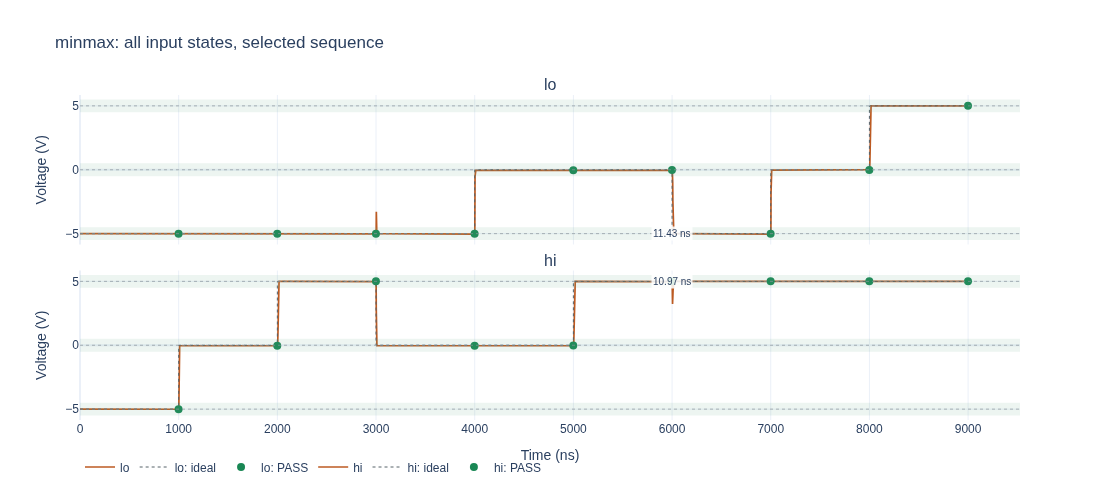

> **What this shows.** minmax passes the integer reference for
> 9 input states. Its 4 mapped cells occupy
> 384 × 366 µm; drawing DRC has 0 markers, LVS is
> Match, and the extracted sequence visits
> 9 input states with output checks PASS.

Use the generated HDL, SPICE, GDS and result files as the starting point for
another ternary design on OpenSUSI TR-1um.


In [15]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('custom', 'Chapter 8: Change the circuit and close the loop', requires=['edit']):
    # Stage includes beside the edited text, preserving the committed source files.
    custom_circuit = load_edited(example,source,BUILD/"your_circuit"/"source"/example.top)
    custom = custom_circuit.synthesize()
    truth = custom_circuit.truth_table()
    pins = custom_circuit.design.inputs
    planned = list(zip(*(truth[p] for p in pins)))
    oracle = example.oracle(pins)
    mapped_truth = evaluate_netlist(custom,{p:truth[p] for p in pins})
    for i, vector in enumerate(planned):
        expected = oracle(vector)
        source_actual = {p:int(truth[p][i]) for p in expected}
        mapped_actual = {p:int(mapped_truth[p][i]) for p in expected}
        if source_actual != expected or mapped_actual != expected:
            raise AssertionError(f"Independent reference disagreement at {dict(zip(pins,vector))}: "
                                 f"expected {expected}, HDL {source_actual}, cells {mapped_actual}. "
                                 "Check your edit; change the arithmetic reference only if you intend a different function.")
    details_html("Edited-circuit exhaustive truth table",truth_table_html(custom,max_rows=len(planned)))

    custom_out = BUILD/"your_circuit"/example.top
    custom_result = cache.run(f"your-{CHOICE}", {"source":source,"net":custom.to_json(),"vectors":planned,
                             "expected":[oracle(v) for v in planned],"load_f":10e-15,"hold_s":1e-6,
                             "step_s":2e-9,"rows":None,"anneal_steps":600,"seed":0,"initialize_internal":True},
        lambda: complete_design(custom,custom_out,planned,oracle,hold_s=1e-6,initialize_internal=True),
        artifacts=lambda r: experiment_artifacts(r,custom_out,example.top))
    assert_experiment(custom_result)
    assert {tuple(row["input_trits"]) for row in custom_result["post"]["measurements"]["rows"]} == set(planned)
    table([["Independent arithmetic input states",len(planned)], ["Physical results",custom_result["stats"]],
           ["DRC clean / LVS matched",[custom_result["drc"]["clean"],custom_result["lvs"]["matched"]]],
           ["Initial Newton guesses (V)",custom_result["initial_nodeset_v"]]],details="Selected circuit physical evidence and Newton guesses")

    # Both drawings below are regenerated from the edited source and its new route.
    custom_inputs = dict(zip(pins,planned[-1],strict=True))
    display(custom.schematic(inputs=custom_inputs,net_names=True,
                             title=f"{custom.top}: schematic of the edited HDL"))
    custom_layout = flow.load_layout(custom,custom_out)
    custom_raster = cache.run(f"your-{CHOICE}-raster",{
        "gds":hashlib.sha256(custom_layout.gds_path.read_bytes()).hexdigest(),"renderer":renderer_sha256},
        lambda:{"png":str(render_gds(custom_layout.gds_path,custom_out/f"{custom.top}.layout.png",top=custom.top))},
        artifacts=lambda r:[r["png"]])
    display(Markdown(f"**Edited `{custom.top}`: actual GDS, DRC-clean and strict-LVS matched.** Axes are in µm."))
    display(Image(filename=custom_raster["png"],width=900))
    show(waveform_figure(custom_result["post"],title=f"{CHOICE}: all input states, selected sequence"))
    custom_values = {"custom.name":custom.top,"custom.logic_states":len(planned),
        "custom.cells":custom.report()["total_cells"],"custom.die_um":dimensions(custom_result["stats"]["die_size_um"]),
        "custom.drc_items":custom_result["drc"]["violations"],"custom.lvs_status":"Match",
        "custom.analog_states":len(set(planned)),"custom.analog_status":"PASS"}
    custom_takeaway = (ROOT/"notebook/narrative/08_your_circuit.md").read_text().split("> **What this shows.**",1)[1]
    display(Markdown(render_narrative("> **What this shows.**"+custom_takeaway,{**narrative_values,**custom_values})))


A deliberately unsupported expression produces a located, readable error before synthesis:


In [16]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('broken', 'Chapter 8: Change the circuit and close the loop', requires=[]):
    from tritflow.hdl import HDLError
    broken = """module broken(input trit a,b,output trit y);
     assign y = a + b;
    endmodule"""
    try:
        flow.loads(broken,"broken",filename="your_circuit.tv")
    except HDLError as error:
        print(error)
        print("Repair: use gates for signal arithmetic; e.g. nany(a,b) gives the negative saturated sum.")
    else:
        raise AssertionError("unsupported signal arithmetic must be rejected")


your_circuit.tv:2:17: arithmetic/comparison on trits is unsupported; use ~, &, |, nany and sized trit literals
Repair: use gates for signal arithmetic; e.g. nany(a,b) gives the negative saturated sum.


## 9. Next: compare the model with silicon

The reference-cell chip is expected in January 2027. Measurement
will connect the divider and timing predictions to real devices: first DC
output levels and static rail currents, then settling with known stimulus
edges and loads. The recorded supply voltages, temperature and probe loading
will define a matching SPICE experiment.

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Measurement</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Record with the result</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Compare with SPICE</th></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Input DC sweep</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Supply voltages, temperature and rail currents</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Transfer curve and middle-level error</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Trit-to-trit step</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Input edge, skew and total output loading</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Final entry into the target voltage band</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Supply and temperature sweep</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Actual operating point at each measurement</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Level and current sensitivity</td></tr>
</table>
</div>

The first comparison will sweep the input through the middle region and
measure the output and each rail current. Next, step between trit levels,
measure final entry into the same voltage bands, and repeat at several loads.
Record pad, package and instrument capacitance alongside the circuit load.
Supply and temperature sweeps can then show which discrepancies depend on
bias and which call for changes to the interconnect or device assumptions.

> **What this shows.** TritFlow provides the predictions, layouts and test
> stimuli for a matched measurement; the middle-level check uses the same
> ±0.5 V target band as the notebook.


## Appendix A. What the results establish

Logical equivalence, physical connectivity and analog settling answer different
questions. The tables in Appendix B identify the checks actually run and the
conditions of each result.

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Topic</th><th width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Scope</th></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Silicon</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">The reference cells were taped out. Silicon has not yet been measured. Adapted standard-cell layouts and generated designs are simulation and layout results.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Operating conditions</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Results use nominal models and the displayed supplies, temperature, input ramps and loads unless an explicitly labelled sweep says otherwise. No statistical mismatch or general PVT guarantee follows.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Logic</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">The HDL describes combinational ternary circuits. It has no sequential logic, <code style="white-space:normal;overflow-wrap:anywhere">x</code>/<code style="white-space:normal;overflow-wrap:anywhere">z</code> semantics or general signal arithmetic operators. Equivalence is exhaustive or sampled as stated for each design.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Analog coverage</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Visiting all input states in one sequence does not test every directed transition or input skew. Larger circuits use labelled carry and arithmetic patterns. Static maxima cover only their listed DC states.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Timing</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Settling means final band entry through the recorded interval, measured from input-ramp start. Sampling and interpolation limit resolution. An unsettled output has no finite reported delay. A longer interval may change a load pass/fail result.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Wire model</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Device extraction uses the PDK LVS deck. Added wire capacitance is a per-net lumped estimate from connected metal area and perimeter with assumed coefficients, not calibrated parasitic extraction. Signal-wire resistance, coupling, distributed poly RC and package effects are absent from the main comparison.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Device comparison</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Equal intrinsic devices establish circuit identity. The metal-capacitance comparison adds geometry-dependent loading; neither comparison establishes full interconnect-RC or silicon equivalence.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Hand estimates</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">The divider uses approximate on-resistances and a simplified resistor model. The ripple estimate repeats a standalone carry stage; the DC cell sum uses the all-zero bias. These are explanatory predictions, not bounds on arbitrary inputs or paths.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Poly resistance</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Optional poly-resistance studies are sensitivity calculations with an assumed gate-poly sheet resistance. Device-resistor and MOS diffusion parameters are not substitutes for a calibrated gate-poly model.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Power delivery</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Divider cells consume static power. The rail-resistance network uses characterized current envelopes and assumed metal/via resistance; it is separate from the ideal-supply SPICE waveforms. Width-scaled published DC limits and reserved margin do not establish lifetime, transient, pad, bond or current-crowding qualification.</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Manufacturing</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Drawing DRC and strict LVS concern the reported core. Mask preparation, mask DRC, padframe, ESD, package and shuttle acceptance require their own evidence. An optional chip wrapper is identified separately; passing its geometry checks alone does not grant shuttle approval.</td></tr>
</table>
</div>

The physical-library and experiment files in Appendix B keep the assumptions
and the tested input plans available for reuse.


## Appendix B. Verification evidence and how to rerun

Each result below links its HDL, library, PDK and native reports. A recorded
result retains the tools and conditions of the run that created it. Reading a
saved report does not execute a new physical or electrical check.

Use the routing realization below to distinguish paper figures from the
four-design results; a circuit name alone does not identify its layout.

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Figure or result set</th><th width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Routing realization</th></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Paper adder overview and placement</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">paper/adder4 · seed 7</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Paper full-adder waveform and load sweep</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">paper/full_add · seed 19</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Paper width sweep</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">width-sweep · seed 7</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Four-design archive: adder4</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/adder4 · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Four-design archive: full_add</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/full_add · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Four-design archive: mac1</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/mac1 · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Four-design archive: mul1</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/mul1 · seed 0</td></tr>
</table>
</div>

The detailed physical and timing tables repeat that identifier in a
**Routing realization** column on every design/output row. The paper and
archived full adders use different routes, so their sum-settling values are
separate measurements even at the same external load and input interval.

For each analog experiment, the expanded table gives the actual input order,
unique states visited, possible states, interval, edge time, maximum timestep,
temperature, external load, initialized segment and pass criteria. Per-output
band errors and settling times accompany the waveforms. Initialization is
excluded from transition maxima. Soft Newton starting guesses, when used,
are listed with the circuit; they do not constrain the transient.

**Run the notebook.** Open the Colab badge and select **Runtime → Run all**.
The setup cell prints the resolved source revision and installed tools.
The default session runs the opening adder and selected editable circuit;
larger sizing, width and load sweeps can read their recorded data. The closing
table labels fresh calculations, local reuse and recorded experiments, with
wall time for each stage. The closing cell prints the measured runtime for this session, including setup.

<details>
<summary>Repeat the calculations</summary>

Set `TRITFLOW_FORCE_RUN=1` before running to recompute expensive notebook stages,
including the shared-design examples. This bypasses both the local result
cache and the recorded shared-design archive. The variable does not regenerate
the separate cell-characterization, sizing, width or load publications.
`TRITFLOW_EXTENDED=1` enables the additional notebook experiments.
The build directory is selected by `TRITFLOW_NOTEBOOK_BUILD`.

From a full checkout with the pinned PDK and tools installed, these commands
regenerate the larger simulation experiments and check their results:

```sh
python3 -m tritflow.sim.sizing
python3 examples/postlayout_all.py
python3 examples/adder_scaling.py --jobs 1
python3 -m tritflow.sim.publication
python3 -m pytest tests/sim tests/extract -q
```

`tritflow.sim.load_sweep.sweep_output_load(directory, destination=...)` repeats
the full-adder load experiment against the generated physical design.
`tritflow.sim.scaling.run_scaling(...)` selects widths and a destination for a
new scaling experiment. Existing inputs and native outputs are checked before
reuse; remove the corresponding experiment output or choose a new destination
to require fresh computation. Failed or missing measurements stay visible.

Run the HDL, synthesis and physical regressions separately when changing those
parts of the flow. Native DRC/LVS reports, SPICE decks, simulator logs and
waveforms are retained beside each generated design.

</details>

<details>
<summary>Sources and licenses</summary>

[TritFlow](https://github.com/PenguinEino/tritflow), the
[author's reference ternary circuits](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic)
and [OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um) provide the design
sources. KLayout packages come from the
[official distribution](https://www.klayout.de/build.html).
The submission includes its Apache-2.0 license and NOTICE; the derived
historical schematic illustrations are released by their author under the
same license. The PDK retains its own license and attribution.

</details>


Free Colab verification at [2c81d2c](https://github.com/PenguinEino/tritflow/commit/2c81d2c1aa81ecebefaa93851f004eb17c9040ba): all 18 code cells completed in 405 s on the successful second Run all (initial setup attempt excluded).

If Run all stops after setup, choose Run all again.


<details><summary>Setup, recovery and source selection</summary>

Colab shallow-clones `colab-v0` into `/content/tritflow`; `TRITFLOW_REF` selects another release.
Use the source revision matching this notebook. Setup preserves Colab's NumPy/SciPy/Matplotlib/Plotly,
checks minimum versions, and prints KLayout/ngspice versions. If mixed versions are detected,
restart once and rerun setup/imports. After a failed chapter, rerun its named prerequisite.
Missing or changed scientific inputs stop execution; changed illustrations only warn.
The closing table distinguishes calculations from recorded experiments.

</details>


In [17]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('characterization', 'Appendix B: Verification evidence and how to rerun', requires=[]):
    characters = {cell: json.loads((CELLS_DIR/f"out/{cell}/{cell}.char.json").read_text())
                  for cell in ["INV","NAND","NOR","NANY","BUF"]}
    rows = [["Cell", "Max DC error (mV)", "Max static rail |I| (µA)", "Input C (fF)", "Suggested fanout"]]
    for cell, char in characters.items():
        assert hashlib.sha256((CELLS_DIR/f"out/{cell}/{cell}.ext.spice").read_bytes()).hexdigest() == char["source_sha256"]
        assert all(hashlib.sha256((PDK_ROOT/"libs.tech/spice/models"/name).read_bytes()).hexdigest() == value
                   for name,value in char["model_sha256"].items()), cell
        assert char["passed"] and all(row["passed"] for row in char["dc"])
        assert len({tuple(row["input_trits"]) for row in char["dc"]}) == 3**len(char["inputs"])
        assert all(result["passed"] for result in char["transient"])
        rows.append([cell, 1e3*max(abs(v) for row in char["dc"] for v in row["error_v"].values()),
                     max(abs(i) for row in char["dc"] for i in row["rail_current_a"].values())*1e6,
                     char["input_capacitance"]["max_f"]*1e15, char["fanout"]["suggested_max"]])
    characterization_rows = rows
    evidence("Full-precision DC checkpoints", {cell:char["dc"] for cell,char in characters.items()})
    table([["Cell", "Recorded conditions", "Tested loads (fF)", "Fanout evidence"]]+
          [[cell, char["conditions"], [r["load_f"]*1e15 for r in char["transient"]], char["fanout"]]
           for cell,char in characters.items()], details="Characterization conditions and complete fanout evidence")
    fanout_rows = [["Cell", "Measured receiver counts", "Chain depth", "Worst chain (ns)",
                    "Driver at largest tested fanout (ns)", "Max level error (mV)"]]
    for cell, char in characters.items():
        cascade = char["cascade"]
        assert cascade["source_sha256"] == char["source_sha256"]
        assert cascade["passed"] and cascade["chains_passed"] and all(c["passed"] for c in cascade["cases"])
        largest = max(cascade["fanouts_tested"])
        chain_times = [t for c in cascade["cases"] if c["mode"] == "chain"
                       for t in c["max_settling_s"].values() if t is not None]
        loaded_times = [c["max_settling_s"]["y0"] for c in cascade["cases"]
                        if c["mode"] == "fanout" and c["fanout"] == largest]
        fanout_rows.append([cell, cascade["fanouts_tested"], cascade["chain_depth"],
                           max(chain_times)*1e9, max(loaded_times)*1e9,
                           max(c["max_error_v"] for c in cascade["cases"])*1e3])


Cell,Recorded conditions,Tested loads (fF),Fanout evidence
INV,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 4; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"
NAND,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 4; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"
NOR,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 3; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"
NANY,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 2; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"
BUF,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 4; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"


In [18]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('four', 'Appendix B: Verification evidence and how to rerun', requires=[]):
    from tritflow.sim.postlayout import representative_vectors, arithmetic_oracle
    FOUR_DESIGN_LOAD_F, FOUR_DESIGN_HOLD_S, FOUR_DESIGN_STEP_S = 10e-15, 500e-9, 2e-9
    four_results = {}
    physical_rows = [["Design", "Routing realization", "Die (µm)", "Aspect", "Utilization", "DRC / LVS", "Input states visited / possible",
                      "Post max error (mV)", "Rail deviation / zero shift (mV)"]]
    timing_rows = [["Design", "Routing realization", "Output", "Device-only max (ns)", "+ wire-C max (ns)", "Largest same-transition change (ns)"]]
    four_run_labels = {}
    for name, source_name, params in [("adder4","adder",{"N":4}), ("full_add","full_add",{}),
                                      ("mac1","mac1",{}), ("mul1","mul1",{})]:
        mapped = flow.load(ROOT/f"examples/{source_name}.tv", source_name, params).synthesize(name=name)
        pins = [p.name for p in mapped.ports if p.dir == "input"]
        planned, labels = representative_vectors(name, pins)
        oracle = arithmetic_oracle(name, pins)
        directory = BUILD/"four_designs"/name
        options = {"net":mapped.to_json(),"vectors":planned,"labels":labels,
                   "expected":[oracle(v) for v in planned],"load_f":FOUR_DESIGN_LOAD_F,
                   "hold_s":FOUR_DESIGN_HOLD_S,"step_s":FOUR_DESIGN_STEP_S,
                   "rows":None,"anneal_steps":600,"seed":0,"initialize_internal":True}
        lookup_started = time.monotonic()
        result = None if cache.force else recorded_campaign.get(name,options)
        if result is not None:
            cache.events.append((f"four-{name}","recorded"))
            cache.timings.append({"stage":f"four-{name}","state":"recorded",
                                  "elapsed_s":time.monotonic()-lookup_started})
            print(f"Recorded {name}: retained native checks; see Appendix B")
        else:
            result = cache.run(f"four-{name}",options,
                lambda: complete_design(mapped,directory,planned,oracle,load_f=FOUR_DESIGN_LOAD_F,
                           hold_s=FOUR_DESIGN_HOLD_S,step_s=FOUR_DESIGN_STEP_S,initialize_internal=True,dataset='four-design'),
                artifacts=lambda r: experiment_artifacts(r,directory,name))
        assert_experiment(result)
        state = 'recorded' if cache.events[-1][1] == 'recorded' else ('fresh' if cache.events[-1][1] == 'run' else 'local reuse')
        if state == 'recorded':
            assert result['routing'] == archive_routing(ROOT/'notebook/assets/four_designs.zip')[name]
        run_label = routing_label(result['routing'],state=state,digest=True)
        four_run_labels[name] = run_label
        assert result["post"]["stimulus"]["vectors"] == list(map(tuple,planned))
        stats, ir = result["stats"], result["ir"]
        rail = max(abs(v) for c in ir["cells"].values() for v in c["rail_deviation_v"].values())
        zero = max(abs(c["zero_level_shift_v"]) for c in ir["cells"].values() if c["zero_level_shift_v"] is not None)
        physical_rows.append([name,run_label,stats["die_size_um"],max(stats["die_size_um"])/min(stats["die_size_um"]),
                              stats["utilization"],[result["drc"]["clean"],result["lvs"]["matched"]],
                              f"{len(set(planned))} / {3**len(pins)}",result["post"]["measurements"]["max_error_v"]*1e3,
                              [rail*1e3,zero*1e3]])
        before, after = [result[mode]["measurements"] for mode in ("pre","post")]
        for pin in after["max_settling_s"]:
            changes = [b["outputs"][pin]["settling_s"]-a["outputs"][pin]["settling_s"]
                       for a,b in zip(before["rows"][1:],after["rows"][1:],strict=True)]
            timing_rows.append([name,run_label,pin,before["max_settling_s"][pin]*1e9,after["max_settling_s"][pin]*1e9,
                                max(changes)*1e9])
        four_results[name] = result


    if recorded_campaign.manifest:
        evidence("Recorded four-design producer tools (not local requalification)",
                 recorded_campaign.manifest["tools"])
    table([["Shared load (fF)",FOUR_DESIGN_LOAD_F*1e15], ["Hold / max step (ns)",
           [FOUR_DESIGN_HOLD_S*1e9,FOUR_DESIGN_STEP_S*1e9]],
           ["Input plan labels", {name:representative_vectors(name,
              r["post"]["stimulus"]["inputs"])[1] for name,r in four_results.items()}]],details="Four-design stimulus conditions and labels")


Recorded adder4: retained native checks; see Appendix B
Recorded full_add: retained native checks; see Appendix B
Recorded mac1: retained native checks; see Appendix B
Recorded mul1: retained native checks; see Appendix B


Shared load (fF),10
Hold / max step (ns),"[500, 2]"
Input plan labels,"adder4: [zero, positive_propagate_setup, positive_carry_through_all_four_digits, positive_carry_release_through_all_four_digits, negative_propagate_setup, negative_carry_through_all_four_digits, negative_carry_release_through_all_four_digits, positive_overflow, negative_overflow, opposite_operands, alternating, alternating_reverse, positive_digit_0, negative_digit_0, positive_digit_1, negative_digit_1, positive_digit_2, negative_digit_2, positive_digit_3, negative_digit_3]; full_add: [exhaustive_0, exhaustive_1, exhaustive_2, exhaustive_3, exhaustive_4, exhaustive_5, exhaustive_6, exhaustive_7, exhaustive_8, exhaustive_9, exhaustive_10, exhaustive_11, exhaustive_12, exhaustive_13, exhaustive_14, exhaustive_15, exhaustive_16, exhaustive_17, exhaustive_18, exhaustive_19, exhaustive_20, exhaustive_21, exhaustive_22, exhaustive_23, exhaustive_24, exhaustive_25, exhaustive_26]; mac1: [exhaustive_0, exhaustive_1, exhaustive_2, exhaustive_3, exhaustive_4, exhaustive_5, exhaustive_6, exhaustive_7, exhaustive_8, exhaustive_9, exhaustive_10, exhaustive_11, exhaustive_12, exhaustive_13, exhaustive_14, exhaustive_15, exhaustive_16, exhaustive_17, exhaustive_18, exhaustive_19, exhaustive_20, exhaustive_21, exhaustive_22, exhaustive_23, exhaustive_24, exhaustive_25, exhaustive_26, exhaustive_27, exhaustive_28, exhaustive_29, exhaustive_30, exhaustive_31, exhaustive_32, exhaustive_33, exhaustive_34, exhaustive_35, exhaustive_36, exhaustive_37, exhaustive_38, exhaustive_39, exhaustive_40, exhaustive_41, exhaustive_42, exhaustive_43, exhaustive_44, exhaustive_45, exhaustive_46, exhaustive_47, exhaustive_48, exhaustive_49, exhaustive_50, exhaustive_51, exhaustive_52, exhaustive_53, exhaustive_54, exhaustive_55, exhaustive_56, exhaustive_57, exhaustive_58, exhaustive_59, exhaustive_60, exhaustive_61, exhaustive_62, exhaustive_63, exhaustive_64, exhaustive_65, exhaustive_66, exhaustive_67, exhaustive_68, exhaustive_69, exhaustive_70, exhaustive_71, exhaustive_72, exhaustive_73, exhaustive_74, exhaustive_75, exhaustive_76, exhaustive_77, exhaustive_78, exhaustive_79, exhaustive_80]; mul1: [exhaustive_0, exhaustive_1, exhaustive_2, exhaustive_3, exhaustive_4, exhaustive_5, exhaustive_6, exhaustive_7, exhaustive_8]"


In [19]:
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('final', 'Appendix B: Verification evidence and how to rerun', requires=['opening', 'gates', 'sizing', 'cells', 'arithmetic', 'synthesis', 'schematic', 'pnr', 'pre', 'published', 'edit', 'custom', 'broken', 'characterization', 'four']):
    table(characterization_rows,details="Cell DC / capacitance / fanout summary")
    table(fanout_rows,details="Transistor-level cascade and fanout tests")
    table(cell_dimension_rows,details="All standard-cell dimensions and pin-access tracks")
    table(cell_qualification_rows,details="Cell drawing-DRC and LVS qualification")
    table(physical_rows,details="Four-design physical and arithmetic checks (retained or fresh as below)")
    table(timing_rows,details="Four-design identical-device timing comparison")
    evidence("Cell ordered-pair/orientation abutments",report["abutment"])
    for name,grid in sizing_grids.items():
        evidence(name+" sizing status including unavailable points",[
            {"index":i,"dimensions":r["dimensions"],"passed":r["passed"],"error":r["error"]}
            for i,r in enumerate(grid["rows"]) if not r["passed"]])
    evidence("Live adder acceptance, sequence and initialized Newton guesses",{
        "logic":net.report()["equivalence"],"labels":vector_labels,"vectors":vectors,
        "measurements":demo["measurements"],"nodeset":demo["initial_nodeset_v"],
        "conditions":{"load_f":LOAD_F,"hold_s":HOLD_S,"edge_s":EDGE_S,"step_s":STEP_S,"temperature_c":TEMP_C}})
    evidence("Native paper-figure inputs and committed image/data hashes",paper)
    table([["Routing realization", "PNR SHA-256", "GDS SHA-256"]]+
          [[routing_label(r),r['pnr_sha256'],r['gds_sha256']]
           for r in (paper['paper_pnr']['routing'],paper['paper_post']['routing'])]+
          [[four_run_labels[name],r['routing']['pnr_sha256'],r['routing']['gds_sha256']]
           for name,r in four_results.items()],details="Native identities for each paper and four-design routing realization")
    assert (runtime_fingerprint(ROOT,PDK_ROOT,names=native_sources) == cache.fingerprint and
            source_manifest(ROOT,PDK_ROOT,names=native_sources) == native_sources), "consumed sources changed during Run all; rerun after publication settles"
    load_paper(ROOT)  # measurements remain strict; illustration changes only warn
    table([["Stage", "Fresh / local cache / recorded", "Wall time this run (s)"]]+[
        [r["stage"],r["state"],round(r["elapsed_s"],3)] for r in sorted(cache.timings,key=lambda r:r["elapsed_s"],reverse=True)])
    table([["Design", "Routing realization", "Measured producer phase", "Wall time (s)", "Process + child CPU time (s)"]]+[
        [name,four_run_labels[name],stage,round(seconds,3),round(result["cpu_times_s"][stage],3)] for name,result in four_results.items()
        for stage,seconds in result["timings_s"].items()],details="Physical and pre/post-SPICE runtime breakdown (producer evidence)")
    print("Cache stages:")
    for name,state in cache.events:
        print(f"  {name}: {state}")
    print(f"Run time including setup: {time.monotonic()-started:.1f} s")
    print("Artifacts:", BUILD)


Cell,Max DC error (mV),Max static rail |I| (µA),Input C (fF),Suggested fanout
INV,39.54,407.2,114.4,8
NAND,102.7,435.4,206.1,8
NOR,159,434.2,278,8
NANY,44.6,421.4,394.1,8
BUF,35.24,814.3,114.4,8


Cell,Measured receiver counts,Chain depth,Worst chain (ns),Driver at largest tested fanout (ns),Max level error (mV)
INV,"[1, 2, 4, 8]",5,15.11,36.03,39.54
NAND,"[1, 2, 4, 8]",5,35.5,65.33,104.3
NOR,"[1, 2, 4, 8]",5,64.53,94.5,158.9
NANY,"[1, 2, 4, 8]",5,70.26,144.9,106.5
BUF,"[1, 2, 4, 8]",5,27.05,37.87,35.66


Cell,Width × common height (µm),Area (µm²),Free full-height M2 tracks
INV,"[108, 132]",1.426e+04,13
NAND,"[144, 132]",1.901e+04,6
NOR,"[144, 132]",1.901e+04,6
NANY,"[168, 132]",2.218e+04,3
BUF,"[216, 132]",2.851e+04,25
TIEP,"[72, 132]",9504,9
TIEZ,"[72, 132]",9504,8
TIEN,"[72, 132]",9504,8
FILL,"[24, 132]",3168,2


Cell,Recorded DRC clean,Recorded LVS qualification,LVS method
INV,True,True,strict device/port comparison
NAND,True,True,strict device/port comparison
NOR,True,True,strict device/port comparison
NANY,True,True,strict device/port comparison
BUF,True,True,strict device/port comparison
TIEP,True,True,strict device/port comparison
TIEZ,True,True,strict device/port comparison
TIEN,True,True,strict device/port comparison
FILL,True,True,empty-device extraction + strict three-rail RR probe fixture


Design,Routing realization,Die (µm),Aspect,Utilization,DRC / LVS,Input states visited / possible,Post max error (mV),Rail deviation / zero shift (mV)
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),"[1740, 2022]",1.162,0.3584,"[True, True]",18 / 19683,43.34,"[19.32, 1.478]"
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),"[876, 702]",1.248,0.5126,"[True, True]",27 / 27,43.34,"[3.741, 0.6847]"
mac1,four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),"[876, 1038]",1.185,0.4721,"[True, True]",81 / 81,43.45,"[6.47, 0.8884]"
mul1,four-design/mul1 · seed 0 · GDS 0f4a46d447b7 (recorded),"[420, 366]",1.148,0.4637,"[True, True]",9 / 9,100.9,"[1.206, 0.3301]"


Design,Routing realization,Output,Device-only max (ns),+ wire-C max (ns),Largest same-transition change (ns)
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),sum[3],201.8,230.1,30.53
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),sum[2],152.9,178.6,26.76
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),sum[1],122.1,148.7,26.53
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),sum[0],122.8,139.2,16.42
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),cout,191.7,221.7,31.49
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),sum,100.3,110.1,15.1
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),cout,90.12,101.5,14.58
mac1,four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),sum,131.9,147.6,17.85
mac1,four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),cout,121.8,135,13.85
mac1,four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),and_out,13.38,15.8,3.14


Routing realization,PNR SHA-256,GDS SHA-256
paper/adder4 · seed 7,e8bbc6eb2c8de6ccd320a0ff775e51817c0fb26735c8581a0ddd048e4f288e6b,c8b426ff5408c656b8a1390d55edc3e89c9aa23378d9ce306648c2a55df93523
paper/full_add · seed 19,653836fddd49e7054008bb63b23830c287a5faa5ef62e77ef73b5ae193b7fbda,3f51bddf7aaa2706b8f8fe85d6f3aa75917fbc4daac7fa291b492c1d29199241
four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),a968235ad5f0f41754f641234d2539dce4c57734679691834e613226bc539567,8a9e5146dd5856e45ae18a090bfea8bf8832aec100996320dd612abf71e619c5
four-design/full_add · seed 0 · GDS e6f70481096a (recorded),d5ea3a7d0355ccc934c17fc373b991318b1613d40855ac4e017a7be04e502b45,e6f70481096ab259602d2be2f9788f664b9368b6a5a6afe4619ab3c92276ff17
four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),0a6607af22683dee4b1004fff811e83745503389ccddcc2881a899690b3012ee,bc2ef6dfb8323d0dc04adc04dd378a55ca05d079e87768d3e8aaf09d20b02496
four-design/mul1 · seed 0 · GDS 0f4a46d447b7 (recorded),3866f8a127f3e4e9015423e87f5d04a049d12175f515ecf41444a52aacbe26ff,0f4a46d447b762b21be18d9e2da2c7a0476c65fee9cb4ff1b17681955e22f1c8


Stage,Fresh / local cache / recorded,Wall time this run (s)
adder2-complete,run,28.54
adder2-pre,run,26.3
your-minmax,run,6.7
inv-dc,run,0.115
your-minmax-raster,run,0.056
four-mac1,recorded,0.033
four-adder4,recorded,0.022
four-full_add,recorded,0.008
four-mul1,recorded,0.002


Design,Routing realization,Measured producer phase,Wall time (s),Process + child CPU time (s)
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),pnr_including_drc,18.46,20.2
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),strict_lvs,0.803,0.799
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),wire_capacitance,0.205,0.205
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),pre_ngspice,55.18,56.45
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),post_ngspice,55.16,56.38
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),pnr_including_drc,1.322,1.322
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),strict_lvs,0.753,0.748
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),wire_capacitance,0.06,0.06
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),pre_ngspice,16.56,17.14
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),post_ngspice,16.47,17.09


Cache stages:
  adder2-complete: run
  inv-dc: run
  adder2-pre: run
  your-minmax: run
  your-minmax-raster: run
  four-adder4: recorded
  four-full_add: recorded
  four-mac1: recorded
  four-mul1: recorded
Run time including setup: 66.6 s
Artifacts: $OUTPUTDIR/flow


<details><summary>Submission identity and capture details</summary>

# TritFlow — Code-a-Chip ISSCC 2027

| Author | Affiliation | Email |
|---|---|---|
| Einosuke Okazaki (岡崎 英之介) | Information and Communication Engineering Course, Department of Monozukuri Engineering, Tokyo Metropolitan College of Industrial Technology (KOSEN), Tokyo, Japan | einosukeokazaki@gmail.com |

Fifth-year student (final year of the five-year KOSEN engineering programme, which combines upper-secondary and the first two years of tertiary education)
GitHub: [PenguinEino](https://github.com/PenguinEino).

Team: TritFlow. Representative: Einosuke Okazaki (岡崎 英之介).

**Apache-2.0.** The author of the historical balanced-ternary-logic project releases the derived schematic assets in this repository under Apache-2.0.

TritFlow connects balanced-ternary circuit design to physical implementation
on OpenSUSI TR-1um. A Verilog-like language describes signed arithmetic using
ternary gates. Synthesis maps those descriptions to a library adapted from
the author's taped-out cells, followed by placement, routing, drawing DRC,
LVS and extracted ngspice simulation. Interactive figures connect schematics,
transfer curves, layouts and waveforms. Hand estimates explain how resistor
and transistor sizing establish the middle voltage, consume static power
and shape ripple-carry delay. Readers can edit a circuit and repeat the flow
in Colab. Reported results distinguish logic coverage, connectivity and
nominal analog behavior; silicon measurements remain future work for validation.

Saved outputs were executed locally, with static PNG figures for reading without running. Animation stills show their initial frame. Machine paths are normalized; numerical results are unchanged. Schematic captures show the selected drawing; rerun to expand alternatives. The original source cells and bootstrap are preserved; rerun them for interactive figures. Free Colab verification at [2c81d2c](https://github.com/PenguinEino/tritflow/commit/2c81d2c1aa81ecebefaa93851f004eb17c9040ba): all 18 code cells completed in 405 s on the successful second Run all (initial setup attempt excluded).

If Run all stops after setup, choose Run all again.

<details><summary>Tool versions observed at packaging (runtime pins are in the bootstrap)</summary>

```json
{
  "numpy": "2.4.3",
  "scipy": "1.17.1",
  "plotly": "7.1.0",
  "klayout": "0.30.6",
  "lark": "1.3.1",
  "matplotlib": "3.10.8",
  "Pillow": "10.2.0",
  "nbformat": "5.10.4",
  "nbclient": "0.10.4",
  "kaleido": "1.5.0",
  "choreographer": "1.4.0",
  "CairoSVG": "2.8.2",
  "python": "3.12.3",
  "ngspice": "ngspice-46+",
  "klayout_binary": "KLayout 0.30.9",
  "static_export_browser": "Google Chrome 152.0.7977.64"
}
```
</details>


</details>